In [53]:
# Predicting party vote shares in European elections – the full project in one notebook
#
# The question: before an election, can we predict what % of the votes each party (and each political bloc)
# will get? And what does that say about France 2027?
#
# The data
# - ParlGov: every national parliament election in Europe, with each party's result, its political family,
#   and the governments (who was in power before each election)
# - World Bank: GDP growth, unemployment and inflation for each country and year
# - Sondax: the 2027 French presidential polls (to compare with our predictions at the end)
#
# How this notebook is organised (each part used to be a separate notebook)
# - Part A – Building the dataset: from the raw files to one clean table (one row = one party in one
#   election), with a new "bloc" column (Far left, Left, Centre, Right, Far right, Other)
# - Part B – Exploring the data: what the table looks like, what seems linked to the vote share
# - Part C – How we measure errors: MAE, RMSE, R², train vs test, cross-validation.
# - Part D – Party model, first steps: baselines, Linear Regression, one decision tree
# - Part E – Ensembles: Bagging, Random Forest, AdaBoost, Gradient Boosting, and the final comparison
# - Part F – Understanding the model: class techniques (heatmap, feature selection, KNN), which features
#   matter, where the model makes mistakes (by party size and by bloc), "accuracy" in %
# - Part G – France 2027 with the party model, compared with the polls
# - Part H – The bloc model: predicting blocs instead of parties, merged with the polls, final 2027 estimate
# - Part I – Conclusions, and how to explain the model in the presentation
#
# 
#
#
# What this step does: imports the libraries and sets the folders. Only PROJECT_DIR needs changing if the
# project moves. The folder "Project Data " (with a space at the end, as on the computer) holds the raw
# files; "data" holds the clean table and the polls file; "models" holds the saved models.
#
# BUILD_FROM_RAW: True = rebuild the clean table from the raw files (Part A). False = skip that and load the
# table already saved in data/party_elections.csv (faster, same result).

import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostRegressor, BaggingRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

# Harmless warning printed many times by some scikit-learn versions when n_jobs=-1
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

PROJECT_DIR = Path("/Users/lena/Documents/IRONHACK DATA /Ironhack Data Analysis/WEEK 7")
RAW_DIR = PROJECT_DIR / "Project Data "                   # ParlGov + World Bank files
DATA_DIR = PROJECT_DIR / "data"
DATA_PATH = DATA_DIR / "party_elections.csv"              # the clean table (built in Part A)
POLLS_PATH = DATA_DIR / "sondages-presidentielle-2027.csv"
MODELS_DIR = PROJECT_DIR / "models"
PARTY_MODEL_PATH = MODELS_DIR / "vote_share_gradient_boosting.joblib"
BLOC_MODEL_PATH = MODELS_DIR / "vote_share_blocs_gradient_boosting.joblib"
BUILD_FROM_RAW = True

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
BLUE, ORANGE, GREY, DARK = "#2a78d6", "#eb6834", "#b4b2a9", "#2e2e2e"   # one colour per job, same in every chart
BLOCS = ["Far left", "Left", "Centre", "Right", "Far right"]            # "Other" is kept but rarely shown
BLOC_COLORS = {"Far left": "#b2182b", "Left": "#ef8a62", "Centre": "#f2b701", "Right": "#2a78d6",
               "Far right": "#3d3d3d", "Other": "#b4b2a9"}


In [54]:
# PART A – BUILDING THE DATASET
#
# Goal: one table where each row = one party in one election, with:
# - the target (what we want to predict): the party's vote share in that election
# - the features (the clues): things known BEFORE the election (past results, was the party in government,
#   its political family, the economy)
#
# We follow one real example all the way through: France, parliament election of June 2022.
#
# The input files
# - view_election.csv: one row = one party in one election. Gives the vote share (target) and the links to
#   the previous election and to the outgoing government
# - view_party.csv: one row = one party. Gives the party family and its left–right position
# - view_cabinet.csv: one row = one party in one government. Tells us if the party was in power
# - World Bank CSVs: one row = one country, one column per year. Give GDP growth, unemployment, inflation
#
# A1. Load the three ParlGov files

if BUILD_FROM_RAW:
    elections = pd.read_csv(RAW_DIR / "view_election.csv", parse_dates=["election_date"])
    party_info_raw = pd.read_csv(RAW_DIR / "view_party.csv")
    cabinets = pd.read_csv(RAW_DIR / "view_cabinet.csv")
    print("elections:", elections.shape, "| parties:", party_info_raw.shape, "| cabinets:", cabinets.shape)

    france_2022_raw = elections[(elections["country_name_short"] == "FRA") & (elections["election_type"] == "parliament")
                                & (elections["election_date"].dt.year == 2022)]
    display(france_2022_raw[["party_name_short", "party_name_english", "vote_share", "seats", "election_id",
                             "previous_parliament_election_id", "previous_cabinet_id", "party_id"]])


elections: (8997, 16) | parties: (1707, 23) | cabinets: (12640, 19)


,party_name_short,party_name_english,vote_share,seats,election_id,previous_parliament_election_id,previous_cabinet_id,party_id
3949,REM|R,The Republic Onwards! | Renaissance,25.75,245.0,1110,1014.0,1673.0,2643
3950,FI,Unbowed France,25.66,131.0,1110,1014.0,1673.0,2644
3951,FN,National Rally,18.68,89.0,1110,1014.0,1673.0,270
3952,UMP|LR,Union for a Popular Movement | The Republicans,10.42,61.0,1110,1014.0,1673.0,658
3953,d-gauche,other left,3.14,22.0,1110,1014.0,1673.0,177
3954,d-droite,other right,2.33,10.0,1110,1014.0,1673.0,285
3955,none,no party affiliation,1.28,10.0,1110,1014.0,1673.0,947
3956,d-centre,other centre,1.25,4.0,1110,1014.0,1673.0,2858
3957,UDI,Union of Democrats and Independents,0.87,3.0,1110,1014.0,1673.0,2273
3958,etc,others,0.85,1.0,1110,1014.0,1673.0,1328


In [55]:
# How to read the result: the raw election file has 8,997 rows (all countries, all election types). France
# 2022 has 14 lines. Three ID columns let us link the files together:
# - party_id: the same party across elections and across files
# - previous_parliament_election_id: which election came just before (2017 for France 2022)
# - previous_cabinet_id: which government was in office during the election (Borne I)
# Notice the fake "parties": "no party affiliation", "one seat", "others", "other left"… They are groups of
# small lists, not real parties.
#
# A2. Filter the elections
#
# What this step does: removes, one filter at a time:
# 1. European Parliament elections: we only want national parliament elections
# 2. Countries outside Europe (Australia, Canada, Japan, Israel, New Zealand, Turkey)
# 3. Placeholder rows (others, no seat, other left…): not real parties
# 4. Rows without a vote share: no target, so useless for learning

EUROPEAN_COUNTRIES = [
    "AUT", "BEL", "BGR", "CHE", "CYP", "CZE", "DEU", "DNK", "ESP", "EST",
    "FIN", "FRA", "GBR", "GRC", "HRV", "HUN", "IRL", "ISL", "ITA", "LTU",
    "LUX", "LVA", "MLT", "NLD", "NOR", "POL", "PRT", "ROU", "SVK", "SVN", "SWE",
]
PLACEHOLDER_SHORT_NAMES = ["none", "no-seat", "one-seat", "etc"]
PLACEHOLDER_NAME_PATTERN = r"^(?:other\b|others$|no party affiliation|no seat|one seat)"

if BUILD_FROM_RAW:
    print(f"Start:                         {len(elections):>5} rows")
    build = elections[elections["election_type"] == "parliament"]
    print(f"Only national parliament:      {len(build):>5} rows")
    build = build[build["country_name_short"].isin(EUROPEAN_COUNTRIES)]
    print(f"Only European countries:       {len(build):>5} rows")
    is_placeholder = (build["party_name_short"].isin(PLACEHOLDER_SHORT_NAMES)
                      | build["party_name_english"].fillna("").str.contains(PLACEHOLDER_NAME_PATTERN))
    build = build[~is_placeholder]
    print(f"Without placeholder 'parties': {len(build):>5} rows")
    build = build[build["vote_share"].notna()].reset_index(drop=True)
    print(f"With a vote share:             {len(build):>5} rows")


Start:                          8997 rows
Only national parliament:       7297 rows
Only European countries:        5962 rows
Without placeholder 'parties':  5652 rows
With a vote share:              5305 rows


In [56]:
# How to read the result: from 8,997 rows we keep 5,305 real parties in national parliament elections in
# 31 European countries. Elections before 1991 are still here: we need them for the "previous result" of
# the 1990s elections. They are removed in step A6.
#
# A3. The party's previous results
#
# Why: the best single clue for a party's score is its score last time.
# What this step does: for each row, finds the same party (party_id) in the previous election
# (previous_parliament_election_id), by merging the table with itself. Then it does the same one step
# further back (the election before the previous one), to see if the party was rising or falling.
# - prev_vote_share: score at the previous election
# - prev2_vote_share: score at the election before that
# - prev_change = prev − prev2: was the party rising or falling?
# - is_new_party = 1 if the party did not run last time (its previous score is then set to 0)

if BUILD_FROM_RAW:
    lookup = build[["election_id", "party_id", "vote_share"]].rename(
        columns={"election_id": "previous_parliament_election_id", "vote_share": "prev_vote_share"})
    build = build.merge(lookup, on=["previous_parliament_election_id", "party_id"], how="left")

    previous_of = build.drop_duplicates("election_id").set_index("election_id")["previous_parliament_election_id"]
    build["prev2_election_id"] = build["previous_parliament_election_id"].map(previous_of)
    lookup2 = lookup.rename(columns={"previous_parliament_election_id": "prev2_election_id",
                                     "prev_vote_share": "prev2_vote_share"})
    build = build.merge(lookup2, on=["prev2_election_id", "party_id"], how="left")

    build["is_new_party"] = build["prev_vote_share"].isna().astype(int)
    build[["prev_vote_share", "prev2_vote_share"]] = build[["prev_vote_share", "prev2_vote_share"]].fillna(0)
    build["prev_change"] = build["prev_vote_share"] - build["prev2_vote_share"]

    display(build[(build["country_name_short"] == "FRA") & (build["election_date"].dt.year == 2022)][
        ["party_name_short", "vote_share", "prev_vote_share", "prev2_vote_share", "prev_change", "is_new_party"]])


,party_name_short,vote_share,prev_vote_share,prev2_vote_share,prev_change,is_new_party
2511,REM|R,25.75,28.21,0.00,28.21,0
2512,FI,25.66,11.03,0.00,11.03,0
2513,FN,18.68,13.20,13.60,-0.40,0
2514,UMP|LR,10.42,15.77,27.12,-11.35,0
2515,UDI,0.87,3.03,0.00,3.03,0
2516,PE,2.67,0.00,0.00,0.00,1
2517,R!,4.24,0.00,0.00,0.00,1


In [57]:
# How to read the result: Renaissance (REM|R) got 28.2% in 2017 and 25.8% in 2022. Reconquête (R!) and
# the Ecologist Party (PE) did not run in 2017, so they are flagged as new parties (is_new_party = 1).
#
# A4. Was the party in government?
#
# Why: voters often punish the parties in power.
# What this step does: keeps the parties of each government (cabinet_party = 1) and merges them on
# (previous_cabinet_id, party_id). If a party matches, it was in the outgoing government:
# - in_government = 1 if the party was in the government in office during the election
# - held_pm = 1 if it held the prime minister

if BUILD_FROM_RAW:
    government_parties = cabinets.loc[cabinets["cabinet_party"] == 1, ["cabinet_id", "party_id", "prime_minister"]]
    government_parties = government_parties.rename(columns={"cabinet_id": "previous_cabinet_id",
                                                            "prime_minister": "held_pm"})
    build = build.merge(government_parties, on=["previous_cabinet_id", "party_id"], how="left")
    build["in_government"] = build["held_pm"].notna().astype(int)
    build["held_pm"] = build["held_pm"].fillna(0).astype(int)

    display(build[(build["country_name_short"] == "FRA") & (build["election_date"].dt.year == 2022)][
        ["party_name_short", "vote_share", "in_government", "held_pm"]])


,party_name_short,vote_share,in_government,held_pm
2511,REM|R,25.75,1,1
2512,FI,25.66,0,0
2513,FN,18.68,0,0
2514,UMP|LR,10.42,0,0
2515,UDI,0.87,0,0
2516,PE,2.67,0,0
2517,R!,4.24,0,0


In [58]:
# How to read the result: in June 2022 only Renaissance was in the government (Borne I) and it held the
# prime minister. All the other French parties were in opposition.
#
# A5. Party family, left–right position and political bloc
#
# What this step does:
# - adds from view_party.csv the party family (social democracy, conservative, right-wing…) and its
#   left–right score, from 0 (far left) to 10 (far right)
# - NEW: groups the families into 6 political blocs, easier to read than 11 families:
#   - Far left: Communist/Socialist (radical left: LFI, PCF, LO in France; Die Linke, Podemos, SYRIZA…)
#   - Left: Social democracy (PS, SPD…) and Green/Ecologist
#   - Centre: Liberal (Renaissance, liberal parties)
#   - Right: Conservative (LR, UDI…), Christian democracy, Agrarian
#   - Far right: Right-wing (RN, Reconquête, AfD, FPÖ…)
#   - Other: Special issue, no family, to be coded (regionalist, single-issue or uncoded parties)
# The bloc is used to read the tables (Parts B, F, G) and to build the bloc model (Part H). It is not
# added as a feature of the party model: it comes from the family, which the model already has, so it
# would add no new information.

FAMILY_TO_BLOC = {
    "Communist/Socialist": "Far left",
    "Social democracy": "Left", "Green/Ecologist": "Left",
    "Liberal": "Centre",
    "Conservative": "Right", "Christian democracy": "Right", "Agrarian": "Right",
    "Right-wing": "Far right",
}

if BUILD_FROM_RAW:
    party_info = party_info_raw[["party_id", "family_name", "left_right"]].rename(
        columns={"left_right": "party_left_right"})
    build = build.merge(party_info, on="party_id", how="left")
    build["bloc"] = build["family_name"].map(FAMILY_TO_BLOC).fillna("Other")

    display(build[(build["country_name_short"] == "FRA") & (build["election_date"].dt.year == 2022)][
        ["party_name_short", "party_name_english", "vote_share", "family_name", "bloc", "party_left_right"]])


,party_name_short,party_name_english,vote_share,family_name,bloc,party_left_right
2511,REM|R,The Republic Onwards! | Renaissance,25.75,Liberal,Centre,6.0000
2512,FI,Unbowed France,25.66,Communist/Socialist,Far left,1.3000
2513,FN,National Rally,18.68,Right-wing,Far right,9.6854
2514,UMP|LR,Union for a Popular Movement | The Republicans,10.42,Conservative,Right,7.4997
2515,UDI,Union of Democrats and Independents,0.87,Conservative,Right,7.4000
2516,PE,Ecologist Party,2.67,Green/Ecologist,Left,2.5000
2517,R!,Reconquest,4.24,Right-wing,Far right,8.8000


In [59]:
# How to read the result: Renaissance is Liberal → Centre (left–right 6.0), RN and Reconquête are
# Right-wing → Far right (9.7 and 8.8), LR and UDI are Conservative → Right, the Ecologists are Left.
# Careful with "FI" (25.66%): ParlGov stores the whole NUPES alliance (LFI + PS + Greens + PCF) under LFI's
# name, so here the whole alliance is in the Far left. Part H fixes this by splitting the alliance between
# Far left and Left.
#
# A6. Election-level features and the time window
#
# What this step does:
# - year: to join the economy and to split train/test by time later
# - n_parties: how many parties ran (more parties = smaller shares for each)
# - keeps elections from 1991 onwards: World Bank unemployment data starts then

if BUILD_FROM_RAW:
    build["year"] = build["election_date"].dt.year
    build["n_parties"] = build.groupby("election_id")["party_id"].transform("count")
    build = build[build["year"] >= 1991].reset_index(drop=True)
    print(f"{len(build)} rows, {build['election_id'].nunique()} elections, "
          f"{build['country_name_short'].nunique()} countries")


2575 rows, 271 elections, 31 countries


In [60]:
# How to read the result: 2,575 party results in 271 elections, in 31 countries, from 1991 to 2023.
#
# A7. The economy (World Bank)
#
# What this step does: the World Bank files are "wide" (one row per country, one column per year). We turn
# them "long" with melt (one row per country and year), then join them on the country code (the World Bank
# uses the same 3-letter codes as ParlGov: FRA, DEU…).
#
# Avoiding leakage (= using information we would not have before the election): an election in June 2022
# cannot know the economy of the full year 2022 (those figures are published in 2023). So each election
# gets the figures of the year before: we add 1 to the year of the economy table before merging.


def load_worldbank(pattern, column_name):
    """Read one World Bank file (skipping its 4 title lines) and turn it into one row per country and year."""
    path = next(p for p in RAW_DIR.rglob(pattern) if "Metadata" not in p.name)
    wide = pd.read_csv(path, skiprows=4)
    year_columns = [c for c in wide.columns if c.isdigit()]
    long = wide.melt(id_vars="Country Code", value_vars=year_columns, var_name="year", value_name=column_name)
    long["year"] = long["year"].astype(int)
    return long.rename(columns={"Country Code": "country_name_short"})


if BUILD_FROM_RAW:
    economy = (load_worldbank("*API_NY.GDP.MKTP.KD.ZG_*.csv", "gdp_growth")
               .merge(load_worldbank("*API_SL.UEM.TOTL.ZS_*.csv", "unemployment"), on=["country_name_short", "year"])
               .merge(load_worldbank("*API_FP.CPI.TOTL.ZG_*.csv", "inflation"), on=["country_name_short", "year"]))
    economy_previous_year = economy.assign(year=economy["year"] + 1)
    build = build.merge(economy_previous_year, on=["country_name_short", "year"], how="left")

    display(build[(build["country_name_short"] == "FRA") & (build["year"] == 2022)][
        ["party_name_short", "vote_share", "gdp_growth", "unemployment", "inflation"]].round(2))


,party_name_short,vote_share,gdp_growth,unemployment,inflation
1074,REM|R,25.75,6.88,7.87,1.64
1075,FI,25.66,6.88,7.87,1.64
1076,FN,18.68,6.88,7.87,1.64
1077,UMP|LR,10.42,6.88,7.87,1.64
1078,UDI,0.87,6.88,7.87,1.64
1079,PE,2.67,6.88,7.87,1.64
1080,R!,4.24,6.88,7.87,1.64


In [61]:
# How to read the result: France 2022 gets the 2021 figures: +6.9% GDP growth (the post-Covid rebound),
# 7.9% unemployment and 1.6% inflation. Every party of the same election gets the same economy.
#
# A8. The final table, saved
#
# What this step does: keeps only the identifiers, the target, the features and the bloc. Columns like
# "seats" are dropped: they are a result of the election, so using them would be cheating (leakage).
# The table is saved in data/party_elections.csv and used by every following part.
#
# Column dictionary
# - vote_share (target): % of votes the party got
# - prev_vote_share: % at the previous election (0 if it didn't run)
# - prev2_vote_share: % at the election before that
# - prev_change: prev − prev2, was the party rising or falling?
# - is_new_party: 1 if the party didn't run last time
# - in_government: 1 if the party was in the outgoing government; held_pm: 1 if it held the prime minister
# - family_name: party family (text, one-hot encoded later); bloc: the political bloc (for reading only)
# - party_left_right: 0 = far left … 10 = far right
# - n_parties: number of parties in that election
# - gdp_growth, unemployment, inflation: economy in the year before the election

FINAL_COLUMNS = [
    # identifiers (not used as features)
    "country_name_short", "election_id", "election_date", "year", "party_id", "party_name_short",
    "party_name_english",
    # target
    "vote_share",
    # features
    "prev_vote_share", "prev2_vote_share", "prev_change", "is_new_party", "in_government", "held_pm",
    "family_name", "party_left_right", "n_parties", "gdp_growth", "unemployment", "inflation",
    # for reading the results (not a feature)
    "bloc",
]

if BUILD_FROM_RAW:
    party_elections = build[FINAL_COLUMNS]
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    party_elections.to_csv(DATA_PATH, index=False)
    print("Saved", DATA_PATH)

party_elections = pd.read_csv(DATA_PATH, parse_dates=["election_date"])
if "bloc" not in party_elections.columns:                 # an older saved table without the bloc column
    party_elections["bloc"] = party_elections["family_name"].map(FAMILY_TO_BLOC).fillna("Other")
print(party_elections.shape)
print("Missing values:", party_elections.isna().sum()[lambda s: s > 0].to_dict())


Saved /Users/lena/Documents/IRONHACK DATA /Ironhack Data Analysis/WEEK 7/data/party_elections.csv
(2575, 21)
Missing values: {'party_left_right': 156, 'gdp_growth': 19, 'unemployment': 96, 'inflation': 50}


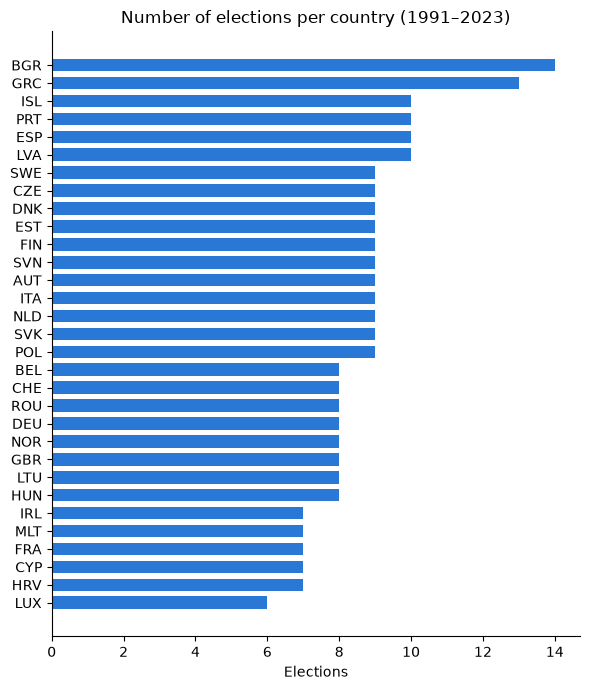

,count,mean,min,25%,50%,75%,max,std
election_date,2575,2007-08-19 16:59:27.844660,1991-03-17 00:00:00,1998-09-30 00:00:00,2007-10-21 00:00:00,2016-03-06 00:00:00,2023-06-25 00:00:00,NaN
year,2575.0,2007.084272,1991.0,1998.0,2007.0,2016.0,2023.0,9.759714
vote_share,2575.0,10.21059,0.05,2.13,5.85,14.3,58.63,11.085226
prev_vote_share,2575.0,9.132644,0.0,0.0,4.5,13.125,68.2,11.677343
prev2_vote_share,2575.0,8.186785,0.0,0.0,2.21,11.575,68.2,11.813293
prev_change,2575.0,0.945859,-65.57,-0.465,0.0,1.9,68.2,6.732586
is_new_party,2575.0,0.261748,0.0,0.0,0.0,1.0,1.0,0.439671
in_government,2575.0,0.212816,0.0,0.0,0.0,0.0,1.0,0.409378
held_pm,2575.0,0.08466,0.0,0.0,0.0,0.0,1.0,0.278429
party_left_right,2419.0,5.207549,0.0,3.2459,5.7167,7.29935,9.8246,2.438388


In [62]:
# How to read the result: 2,575 rows and 21 columns. A few values are missing: the left–right score of 156
# small parties and some economy years. They are filled in Part D (with the median of the column).
#
# PART B – EXPLORING THE DATA
#
# B1. How many elections per country, and the summary of the numbers
#
# What this step does: counts the elections of each country, and shows the summary of each numeric column
# (count, average, minimum, quartiles, maximum).

elections_per_country = party_elections.groupby("country_name_short")["election_id"].nunique().sort_values()
fig, ax = plt.subplots(figsize=(6, 7))
ax.barh(elections_per_country.index, elections_per_country.values, color=BLUE, height=0.7)
ax.set(title="Number of elections per country (1991–2023)", xlabel="Elections")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

party_elections.drop(columns=["election_id", "party_id"]).describe().T.round(2)


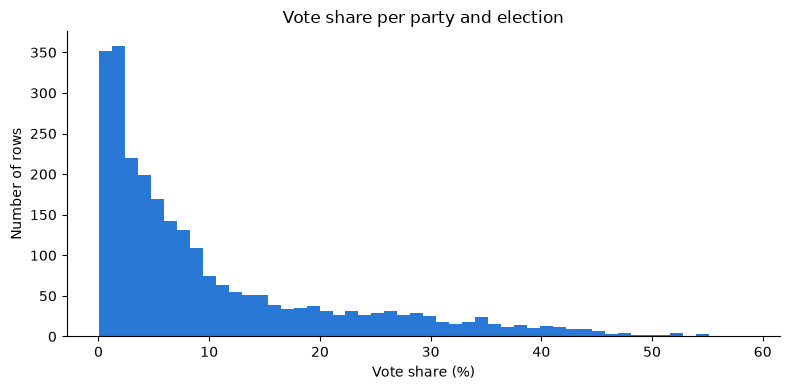

In [63]:
# How to read the result: each country has between 6 (Luxembourg) and 14 (Bulgaria) elections in our window. The summary
# shows:
# - vote_share: on average 10.2%, from 0.05% to 58.6%. The median (50%) is only 5.9%: there are many small
#   parties and a few big ones.
# - is_new_party: 26% of the rows are parties that did not run last time.
# - in_government: 21% of the parties were in the outgoing government.
# - inflation: a maximum of 951%! (Eastern Europe in the early 1990s). We cap it at 50% in Part D.
#
# B2. The target: how are vote shares spread?

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(party_elections["vote_share"], bins=50, color=BLUE)
ax.set(title="Vote share per party and election", xlabel="Vote share (%)", ylabel="Number of rows")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


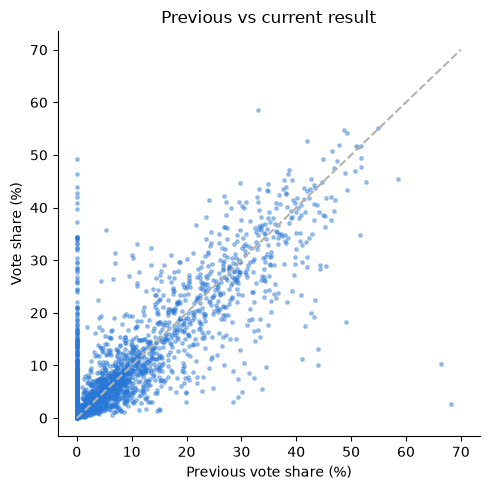

In [64]:
# How to read the chart: most rows are on the left (small parties under 10%) and a long tail goes to the
# right (a few big parties at 30–50%). This shape matters for the errors: a big party can move many
# points, a small one cannot.
#
# B3. The baseline idea: "same as last time"
#
# What this step does: draws each party's score against its score at the previous election. If parties
# kept the same score, all dots would be on the dashed line. This is the simplest possible prediction, and
# every model must beat it.

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(party_elections["prev_vote_share"], party_elections["vote_share"], s=6, alpha=0.4, color=BLUE)
ax.plot([0, 70], [0, 70], color=GREY, linestyle="--")
ax.set(xlabel="Previous vote share (%)", ylabel="Vote share (%)", title="Previous vs current result")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


In [65]:
# How to read the chart: most dots are close to the dashed line: a party's last score is a very strong
# clue. The dots on the left edge (previous score 0) are new parties: they can get anything, which is hard
# to predict. Dots far from the line are surprises (collapses, surges, alliances).
#
# B4. The parties by bloc
#
# What this step does: for each bloc, counts the party rows, the average score of one party, and the
# average total score of the bloc in an election (all its parties added up).

bloc_totals = party_elections.groupby(["election_id", "bloc"])["vote_share"].sum().rename("bloc_total").reset_index()
bloc_summary = pd.DataFrame({
    "party rows": party_elections["bloc"].value_counts(),
    "average % of one party": party_elections.groupby("bloc")["vote_share"].mean(),
    "average % of the whole bloc in an election": bloc_totals.groupby("bloc")["bloc_total"].mean(),
}).reindex(BLOCS + ["Other"])
bloc_summary.round(1)


,party rows,average % of one party,average % of the whole bloc in an election
bloc,,,
Far left,285,6.1,9.5
Left,615,13.6,30.9
Centre,377,9.7,16.6
Right,762,13.0,36.6
Far right,297,7.0,11.4
Other,239,2.5,4.5


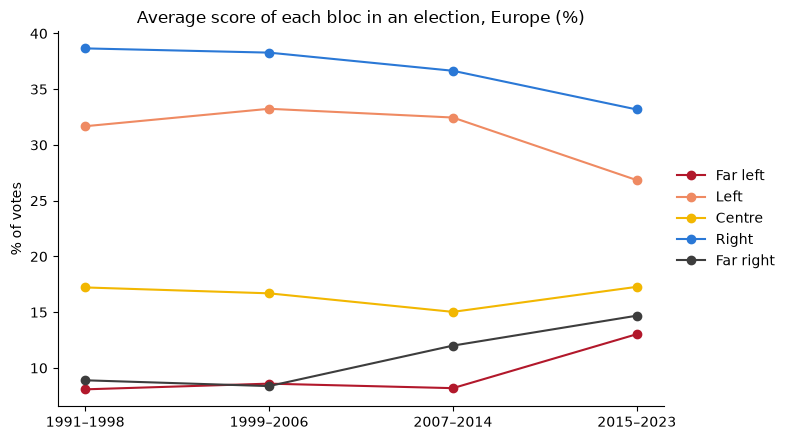

bloc,Far left,Left,Centre,Right,Far right
period,,,,,
1991–1998,8.1,31.7,17.2,38.7,8.9
1999–2006,8.6,33.2,16.7,38.3,8.4
2007–2014,8.2,32.5,15.0,36.7,12.0
2015–2023,13.0,26.8,17.3,33.2,14.7


In [66]:
# How to read the table:
# - The Right (conservatives, Christian democrats, agrarians) and the Left (social democrats, greens) are
#   the two big blocs: about 37% and 31% of the votes in an average election.
# - The Centre gets about 17%, the Far right 11% and the Far left 10% on average (when they run).
# - One far-left or far-right party is small on average (6–7%), while one social democratic or conservative
#   party is about twice as big (13–14%).
#
# B5. How the blocs changed in Europe since 1991
#
# What this step does: for each period, the average total score of each bloc in an election (when the bloc
# ran). This shows the big trends that the models will have to deal with.

bloc_totals = bloc_totals.merge(party_elections[["election_id", "year"]].drop_duplicates(), on="election_id")
bloc_totals["period"] = pd.cut(bloc_totals["year"], [1990, 1998, 2006, 2014, 2023],
                               labels=["1991–1998", "1999–2006", "2007–2014", "2015–2023"])
bloc_trend = bloc_totals.pivot_table(index="period", columns="bloc", values="bloc_total", aggfunc="mean",
                                     observed=True)[BLOCS]

fig, ax = plt.subplots(figsize=(8, 4.5))
for bloc in BLOCS:
    ax.plot(bloc_trend.index.astype(str), bloc_trend[bloc], marker="o", color=BLOC_COLORS[bloc], label=bloc)
ax.set(title="Average score of each bloc in an election, Europe (%)", ylabel="% of votes")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
bloc_trend.round(1)


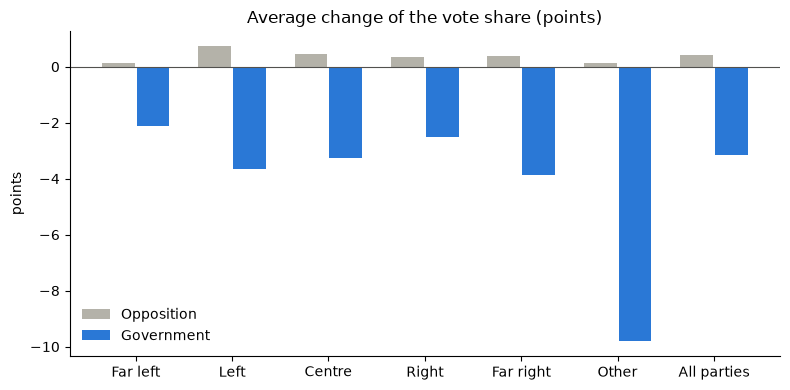

,Opposition,Government
bloc,,
Far left,0.12,-2.12
Left,0.74,-3.65
Centre,0.45,-3.25
Right,0.36,-2.52
Far right,0.38,-3.86
Other,0.13,-9.81
All parties,0.41,-3.15


In [67]:
# How to read the chart and the table: the big change is in the last period (2015–2023):
# - the Far right grows from about 9% (1990s) to 12% (2007–2014) and 15% (2015–2023)
# - the Far left grows from about 8% to 13% in 2015–2023 (SYRIZA, Podemos, LFI…)
# - the Left falls from 32–33% to 27%, the Right from 38–39% to 33%
# So the test years (2015–2023) are a time of big change: patterns learned on 1991–2014 will not always
# work. This explains a lot of the results of Parts E and H.
#
# B6. Does governing cost votes?
#
# What this step does: for parties that ran last time, the average change of their score (this time − last
# time), for parties in the outgoing government and for the opposition, overall and by bloc.

existing = party_elections[party_elections["is_new_party"] == 0].assign(
    change=lambda d: d["vote_share"] - d["prev_vote_share"])
change_by_role = existing.pivot_table(index="bloc", columns="in_government", values="change", aggfunc="mean")
change_by_role.columns = ["Opposition", "Government"]
change_by_role.loc["All parties"] = existing.groupby("in_government")["change"].mean().to_numpy()
change_by_role = change_by_role.reindex(BLOCS + ["Other", "All parties"])

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(change_by_role))
ax.bar(positions - 0.18, change_by_role["Opposition"], width=0.34, color=GREY, label="Opposition")
ax.bar(positions + 0.18, change_by_role["Government"], width=0.34, color=BLUE, label="Government")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xticks(positions, change_by_role.index)
ax.set(title="Average change of the vote share (points)", ylabel="points")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
change_by_role.round(2)


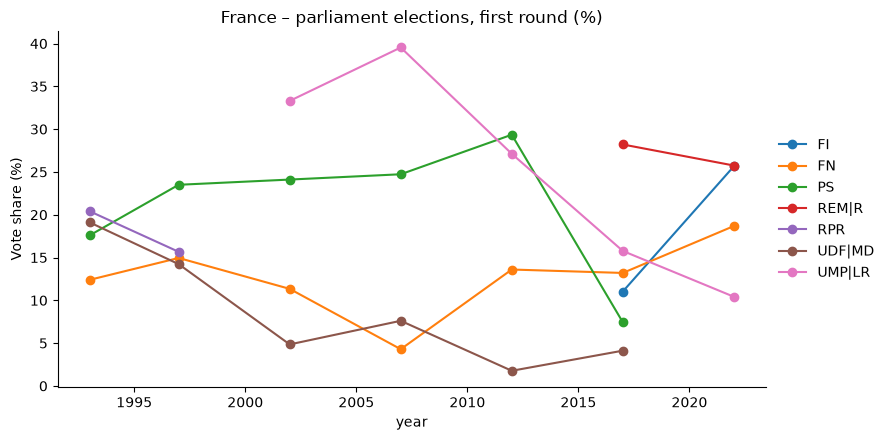

In [68]:
# How to read the result: governing costs votes, in every bloc. On average a party in the outgoing
# government loses 3.2 points, while an opposition party gains 0.4. The cost is biggest for the Left (−3.7)
# and the Far right (−3.9), smallest for the Far left (−2.1) and the Right (−2.5). (For "Other", −9.8 comes
# from very few governing parties, so it is not reliable.) This is why in_government and held_pm are
# features of the model.
#
# B7. Focus on France, by party
#
# What this step does: draws the 7 biggest French parties since 1993, as they are stored in ParlGov.

france_parties = party_elections[party_elections["country_name_short"] == "FRA"]
main_parties = france_parties.groupby("party_name_short")["vote_share"].max().nlargest(7).index
france_pivot = france_parties[france_parties["party_name_short"].isin(main_parties)].pivot_table(
    index="year", columns="party_name_short", values="vote_share")

fig, ax = plt.subplots(figsize=(9, 4.5))
france_pivot.plot(marker="o", ax=ax)
ax.set(title="France – parliament elections, first round (%)", ylabel="Vote share (%)")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


In [69]:
# How to read the chart: PS and UMP/LR dominate until 2012, then collapse in 2017 when Macron's REM appears
# (28%). The FN/RN grows slowly. FI jumps from 11% to 26% in 2022, but only because ParlGov codes the whole
# NUPES alliance (LFI + PS + Greens + PCF) under FI. This is the "alliance problem" that Part H solves with
# blocs.
#
# B8. Average vote share by party family

by_family = party_elections.groupby("family_name").agg(
    average_vote_share=("vote_share", "mean"), rows=("vote_share", "size"), bloc=("bloc", "first"))
by_family.sort_values("average_vote_share").round(2)


,average_vote_share,rows,bloc
family_name,,,
Special issue,2.15,206,Other
to be coded,2.41,23,Other
Green/Ecologist,5.22,200,Left
Communist/Socialist,6.06,285,Far left
Right-wing,6.97,297,Far right
no family,8.81,10,Other
Liberal,9.71,377,Centre
Agrarian,10.91,101,Right
Christian democracy,11.98,271,Right


In [70]:
# How to read the table: social democrats, conservatives and Christian democrats are on average the
# biggest parties (big traditional parties). Special issue and "to be coded" parties are small. The family
# gives the model a rough idea of a party's usual size.
#
# B9. Which numeric columns move together with the vote share?
#
# What this step does: the correlation between each numeric column and the vote share. A correlation is a
# number between −1 and 1 that says how much two columns move together in a straight line:
# - close to 1: when one goes up, the other goes up too
# - close to −1: when one goes up, the other goes down
# - close to 0: no straight-line link

numeric_columns = ["prev_vote_share", "prev2_vote_share", "prev_change", "is_new_party", "in_government",
                   "held_pm", "party_left_right", "n_parties", "gdp_growth", "unemployment", "inflation"]
party_elections[numeric_columns + ["vote_share"]].corr()["vote_share"].drop("vote_share").sort_values().round(3)


n_parties          -0.291
is_new_party       -0.242
unemployment       -0.052
inflation          -0.040
gdp_growth          0.042
party_left_right    0.051
prev_change         0.111
in_government       0.327
held_pm             0.469
prev2_vote_share    0.742
prev_vote_share     0.814
Name: vote_share, dtype: float64

In [71]:
# How to read the result: the previous score (0.81) and the score before (0.74) are by far the strongest
# links. Holding the prime minister (0.47) and being in government (0.33) go with bigger scores, because
# the PM's party is usually a big party. More parties in the election (−0.29) means smaller shares each. The
# economy is close to 0: on its own, it has almost no straight-line link with the vote share.
#
# PART C – HOW WE MEASURE ERRORS (explained once, used everywhere)
#
# Our model predicts a number (a vote share), so this is a regression problem. We never expect the
# prediction to be exactly right, so we measure HOW FAR it is from the real result.
#
# 1. MAE – Mean Absolute Error (our main metric)
#    - For each party: error = |real − predicted|, without the sign. Predict 25% for a party that gets 22%:
#      error 3 points. Predict 20%: error 2 points.
#    - MAE = the average of these errors. MAE = 3.15 means "on average, the prediction is 3.15 points away
#      from the real result". Lower is better, 0 would be perfect.
#    - It is in points of vote share, so it is the easiest to explain.
#
# 2. RMSE – Root Mean Squared Error
#    - Same idea, but each error is squared before the average, then we take the square root at the end.
#    - Squaring makes big mistakes count much more: a 10-point miss counts like 100, a 2-point miss like 4.
#    - RMSE is always ≥ MAE. If RMSE is much bigger than MAE, the model makes a few big mistakes.
#
# 3. R² – share of the differences explained
#    - Compares the model with the laziest possible guess: giving every party the average score.
#    - R² = 1: perfect. R² = 0: no better than the average. R² = 0.75: the model explains 75% of the
#      differences between parties. Higher is better.
#
# 4. Against what? The baseline
#    - A number alone means nothing, so we always compare with a very simple guess, the baseline: "each party
#      gets the same score as last time". If a model can't beat it, it is useless.
#
# 5. Train vs test, and overfitting
#    - Train = the elections the model learns from (1991–2014). Test = the elections it never sees while
#      learning (2015–2023), like a real future election.
#    - If the train error is much lower than the test error, the model learned the training years "by
#      heart" instead of general rules: that's overfitting. The gap (test MAE − train MAE) shows it.
#
# 6. Cross-validation (to choose the settings without touching the test)
#    - The training years are cut into 5 parts. The model learns on 4 parts and is checked on the 5th, five
#      times. The average error is the "cross-validation MAE".
#    - GroupKFold keeps all the parties of one election in the same part, so the model is always checked
#      on elections it has never seen.
#
# 7. "Accuracy" in %
#    - Accuracy (% of correct answers) is for classification (yes/no answers). For a number, it would be
#      about 0%. In Part F we turn the errors into yes/no questions ("within 5 points?") to give easy %.
#
# A small example to see the three metrics: 4 parties, real results 30, 20, 10 and 5%, and two models.
# Model A is always a bit wrong. Model B is exactly right three times and very wrong once.

example = pd.DataFrame({"real": [30, 20, 10, 5], "model A": [27, 22, 12, 6], "model B": [30, 20, 10, 15]})
example_scores = pd.DataFrame({
    name: {"MAE": mean_absolute_error(example["real"], example[name]),
           "RMSE": np.sqrt(mean_squared_error(example["real"], example[name])),
           "R²": r2_score(example["real"], example[name])}
    for name in ["model A", "model B"]}).T
display(example)
example_scores.round(2)


,real,model A,model B
0,30,27,30
1,20,22,20
2,10,12,10
3,5,6,15


,MAE,RMSE,R²
model A,2.0,2.12,0.95
model B,2.5,5.00,0.73


In [72]:
# How to read the example:
# - Model A misses by 3, 2, 2 and 1 points: MAE = 8 / 4 = 2.0. Model B misses by 0, 0, 0 and 10: MAE = 10 / 4
#   = 2.5. On the average error, A is better.
# - RMSE: A = 2.12, B = 5.0. B's single 10-point miss is punished hard: that's what RMSE is for.
# - R²: A = 0.95, B = 0.73. Both explain most of the differences between the 4 parties, A more so.
# So two models can look close on MAE and very different on RMSE: we look at both.
#
# PART D – PARTY MODEL, FIRST STEPS
#
# D1. Helper functions and the final features
#
# What this step does: defines, once, the small functions used in all the following parts:
# - add_features: fixes two data problems found in Part B and adds two election-level features:
#   1. prev_change: a party that did not exist two elections ago has prev2_vote_share = 0, so its "change"
#      looked like a huge surge (REM 2022: +28 points). We set it to 0 and flag those parties with
#      was_new_last_time = 1 instead.
#   2. inflation capped at 50%, so a few hyperinflation years don't dominate.
#   3. n_new_parties: how many newcomers run in the election (they take votes from the others).
#   4. prev_total_running: share of the last vote held by the parties running now. Low = many votes are
#      "up for grabs". Both are known once the lists are registered, before the vote.
# - time_split: older elections for training, recent ones for testing
# - build_pipeline: the preparation steps + the model in one object (fill missing values with the median,
#   scale the numbers if asked, one-hot encode the party family). Everything is learned on the training
#   data only, so no information leaks from the test.
# - the two baselines, and evaluate: computes all the metrics of Part C for one model and stores them

TARGET = "vote_share"
TEST_START_YEAR = 2015          # train on elections before this year, test on this year and after
INFLATION_CAP = 50              # % – caps the early-1990s hyperinflation outliers (up to 951%)

NUMERIC_FEATURES = [
    "prev_vote_share", "prev2_vote_share", "prev_change", "is_new_party", "was_new_last_time",   # past results
    "in_government", "held_pm",                                                                # power
    "party_left_right",                                                                        # identity
    "n_parties", "n_new_parties", "prev_total_running",                                        # the election
    "gdp_growth", "unemployment", "inflation",                                                 # economy
]
CATEGORICAL_FEATURES = ["family_name"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES


def add_features(table):
    """Fix prev_change, cap inflation and add the election-level features (see the comment above)."""
    table = table.copy()
    no_result_two_elections_ago = table["prev2_vote_share"] == 0
    table["was_new_last_time"] = (no_result_two_elections_ago & (table["prev_vote_share"] > 0)).astype(int)
    table.loc[no_result_two_elections_ago, "prev_change"] = 0
    table["inflation"] = table["inflation"].clip(upper=INFLATION_CAP)
    table["n_new_parties"] = table.groupby("election_id")["is_new_party"].transform("sum")
    table["prev_total_running"] = table.groupby("election_id")["prev_vote_share"].transform("sum")
    return table


def time_split(table, start_year=TEST_START_YEAR):
    """Older elections for training, recent ones for testing: the model never sees the future."""
    return table[table["year"] < start_year].copy(), table[table["year"] >= start_year].copy()


def build_pipeline(model, numeric_features=NUMERIC_FEATURES, scaler="standard"):
    """Fill gaps with the median → scale (scaler=None for trees) → one-hot encode the family → model."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scaler == "standard":
        numeric_steps.append(("scale", StandardScaler()))
    elif scaler == "minmax":
        numeric_steps.append(("scale", MinMaxScaler()))
    preparation = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), list(numeric_features)),
        ("family", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
    ])
    return Pipeline([("prep", preparation), ("model", model)])


def naive_prediction(table):
    """Baseline 1: 'same score as last time' (0% for a new party)."""
    return table["prev_vote_share"].to_numpy()


def smarter_naive_prediction(table, train_table):
    """Baseline 2: same as last time, but a new party gets the median score of new parties in training."""
    typical_newcomer = train_table.loc[train_table["is_new_party"] == 1, TARGET].median()
    return np.where(table["is_new_party"] == 1, typical_newcomer, table["prev_vote_share"])


def clip_shares(predictions):
    """A vote share can't be negative or above 100%."""
    return np.clip(predictions, 0, 100)


def evaluate(name, train_predictions, test_predictions, table=None):
    """Compute the metrics of Part C for one model, store them in `table` (default: scores) and print them."""
    table = scores if table is None else table
    test_errors = np.abs(y_test.to_numpy() - test_predictions)
    is_new = test["is_new_party"].to_numpy() == 1
    table[name] = {
        "test MAE": test_errors.mean(),
        "MAE existing parties": test_errors[~is_new].mean(),
        "MAE new parties": test_errors[is_new].mean(),
        "test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "test R²": r2_score(y_test, test_predictions),
        "train MAE": mean_absolute_error(y_train, train_predictions),
    }
    row = table[name]
    print(f"{name}: test MAE {row['test MAE']:.2f} | RMSE {row['test RMSE']:.2f} | R² {row['test R²']:.3f} "
          f"| train MAE {row['train MAE']:.2f}")
    return test_predictions


def evaluate_model(name, fitted_model, table=None):
    """Same as evaluate, for a fitted pipeline: predicts the train and test years itself."""
    return evaluate(name, clip_shares(fitted_model.predict(X_train)), clip_shares(fitted_model.predict(X_test)), table)


In [73]:
# D2. Load the table, fix the features, split by time
#
# What this step does: applies add_features, then cuts the data in two:
# - train = elections from 1991 to 2014: the models learn from these
# - test = elections from 2015 to 2023: never seen while learning, only used to measure the result
# Why by time and not randomly? In real life we always predict the future from the past. A random split
# would let the model learn from a 2020 election and then "predict" a 2010 one, which looks too good.
# X = the features (the clues), y = the target (the vote share).

df = add_features(party_elections)
train, test = time_split(df)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
cv = GroupKFold(n_splits=5)
groups = train["election_id"]

display(df[(df["country_name_short"] == "FRA") & (df["year"] == 2022)][
    ["party_name_short", "bloc", "vote_share", "prev_vote_share", "prev2_vote_share", "prev_change",
     "was_new_last_time", "is_new_party", "n_new_parties", "prev_total_running"]])

pd.DataFrame({
    "rows": [len(train), len(test)],
    "elections": [train["election_id"].nunique(), test["election_id"].nunique()],
    "years": [f"{train['year'].min()}–{train['year'].max()}", f"{test['year'].min()}–{test['year'].max()}"],
    "share of new parties": [train["is_new_party"].mean().round(2), test["is_new_party"].mean().round(2)],
}, index=["train", "test"])


,party_name_short,bloc,vote_share,prev_vote_share,prev2_vote_share,prev_change,was_new_last_time,is_new_party,n_new_parties,prev_total_running
1074,REM|R,Centre,25.75,28.21,0.00,0.00,1,0,2,71.24
1075,FI,Far left,25.66,11.03,0.00,0.00,1,0,2,71.24
1076,FN,Far right,18.68,13.20,13.60,-0.40,0,0,2,71.24
1077,UMP|LR,Right,10.42,15.77,27.12,-11.35,0,0,2,71.24
1078,UDI,Right,0.87,3.03,0.00,0.00,1,0,2,71.24
1079,PE,Left,2.67,0.00,0.00,0.00,0,1,2,71.24
1080,R!,Far right,4.24,0.00,0.00,0.00,0,1,2,71.24


,rows,elections,years,share of new parties
train,1809,196,1991–2014,0.27
test,766,75,2015–2023,0.24


In [74]:
# How to read the result:
# - France 2022: REM and FI now have prev_change = 0 and was_new_last_time = 1 instead of fake momentum.
#   The election had 2 newcomers (PE and Reconquête), and the parties running in 2022 had won 71% of the
#   2017 vote between them.
# - The split: 1,809 rows (196 elections) for training, 766 rows (75 elections) for testing, about 70/30.
#   Both have about 1 new party in 4, so the test is not unusually easy or hard.
#
# D3. The two baselines – the scores to beat
#
# - Baseline 1 "same as last time": each party gets its previous score (so 0% for a new party)
# - Baseline 2 "smarter": the same, but a new party gets the typical (median) score of newcomers in the
#   training years
# The table also splits the MAE between existing parties and new parties.

scores = {}
evaluate("Baseline: same as last time", naive_prediction(train), naive_prediction(test))
evaluate("Baseline: smarter (newcomers get median)", smarter_naive_prediction(train, train),
         smarter_naive_prediction(test, train))
pd.DataFrame(scores).T.round(2)


Baseline: same as last time: test MAE 3.59 | RMSE 5.59 | R² 0.683 | train MAE 4.25
Baseline: smarter (newcomers get median): test MAE 3.26 | RMSE 5.23 | R² 0.723 | train MAE 3.86


,test MAE,MAE existing parties,MAE new parties,test RMSE,test R²,train MAE
Baseline: same as last time,3.59,3.38,4.29,5.59,0.68,4.25
Baseline: smarter (newcomers get median),3.26,3.38,2.90,5.23,0.72,3.86


In [75]:
# How to read the result: baseline 1 is off by 3.59 points on average (MAE). Its RMSE is 5.59 (a few
# parties move a lot) and its R² is already 0.68: copying last time's score explains two thirds of the
# differences between parties. Most of its trouble comes from new parties (4.29 points), because it gives
# them 0%. Just giving newcomers a typical score (baseline 2) drops the MAE to 3.26.
#
# D4. Linear Regression
#
# What it does: fits a straight-line formula: vote share = a × feature 1 + b × feature 2 + … The numbers
# are scaled, so each coefficient (a, b…) says how many points the prediction moves for one "typical
# step" of that feature. We show the biggest ones to see what it learned.

linear = build_pipeline(LinearRegression()).fit(X_train, y_train)
linear_predictions = evaluate_model("Linear Regression", linear)

coefficients = pd.Series(linear.named_steps["model"].coef_, index=linear.named_steps["prep"].get_feature_names_out())
coefficients.index = coefficients.index.str.replace("numeric__", "").str.replace("family__family_name_", "family: ")
coefficients[coefficients.abs() > 0.3].sort_values().round(2)


Linear Regression: test MAE 3.73 | RMSE 5.19 | R² 0.727 | train MAE 4.01


family: to be coded           -3.32
family: Special issue         -3.01
prev_total_running            -1.74
n_new_parties                 -1.37
family: Communist/Socialist   -1.34
family: Green/Ecologist       -1.12
in_government                 -1.11
family: Right-wing            -0.80
n_parties                     -0.37
family: Christian democracy    0.55
family: Agrarian               0.55
was_new_last_time              0.66
prev_change                    1.15
family: Conservative           1.98
is_new_party                   2.07
family: Social democracy       2.39
family: no family              3.89
prev2_vote_share               4.15
prev_vote_share                6.43
dtype: float64

Decision Tree (depth 2): test MAE 4.10 | RMSE 5.64 | R² 0.677 | train MAE 4.63
Decision Tree (depth 3): test MAE 3.84 | RMSE 5.45 | R² 0.699 | train MAE 4.37
Decision Tree (depth 4): test MAE 3.59 | RMSE 5.23 | R² 0.723 | train MAE 3.95
Decision Tree (depth 5): test MAE 3.60 | RMSE 5.28 | R² 0.717 | train MAE 3.65
Decision Tree (depth 6): test MAE 3.85 | RMSE 5.68 | R² 0.673 | train MAE 3.34
Decision Tree (depth 8): test MAE 3.86 | RMSE 5.79 | R² 0.660 | train MAE 2.51
Decision Tree (depth 10): test MAE 4.14 | RMSE 6.51 | R² 0.570 | train MAE 1.65
Decision Tree (depth 15): test MAE 4.59 | RMSE 7.00 | R² 0.503 | train MAE 0.48


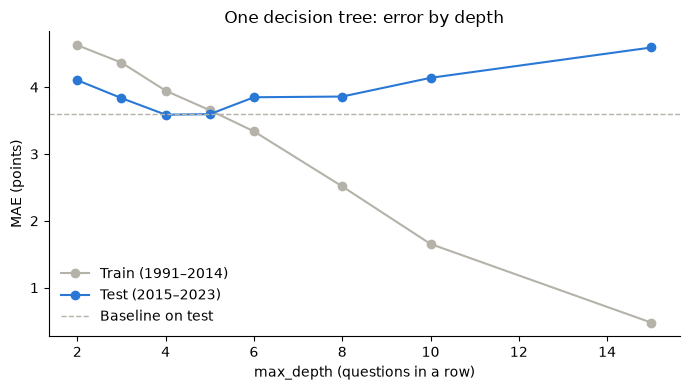

In [76]:
# How to read the result: a positive coefficient pushes the prediction up, a negative one pushes it down.
# It learned sensible things: the last two scores push up a lot, being in government pushes down, more
# newcomers in the race means smaller shares for the others. But its MAE (3.73) is worse than both
# baselines: a straight line can't capture that a 30% party and a 3% party behave very differently.
#
# D5. One decision tree
#
# What a decision tree does: it asks a series of yes/no questions, like a game of "20 questions":
# "Was the party above 15% last time?" → yes → "Did it hold the prime minister?" → yes → predict 27%.
# At the end of each branch (a leaf), the prediction is the average score of the training parties there.
# The two main settings:
# - max_depth: how many questions in a row. More = more detailed, but more risk of memorising.
# - min_samples_leaf: the minimum number of parties in a leaf. Bigger = more cautious.
# Trees need no scaling: they only ask "above or below this value?", and the questions stay readable in
# real units ("prev_vote_share ≤ 15.3%").
#
# D5a. How deep should a tree be?
#
# What this step does: trains trees from 2 to 15 questions deep and draws their train and test errors.
# We look at the curve to understand overfitting; the depth itself is chosen by cross-validation in D5b
# (choosing it from the test would turn the exam into practice).

depth_scores = {}
depths = [2, 3, 4, 5, 6, 8, 10, 15]
for depth in depths:
    tree = build_pipeline(DecisionTreeRegressor(max_depth=depth, random_state=0), scaler=None).fit(X_train, y_train)
    evaluate_model(f"Decision Tree (depth {depth})", tree, depth_scores)

depth_table = pd.DataFrame(depth_scores).T
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, depth_table["train MAE"], marker="o", color=GREY, label="Train (1991–2014)")
ax.plot(depths, depth_table["test MAE"], marker="o", color=BLUE, label="Test (2015–2023)")
ax.axhline(scores["Baseline: same as last time"]["test MAE"], color=GREY, linestyle="--", linewidth=1,
           label="Baseline on test")
ax.set(title="One decision tree: error by depth", xlabel="max_depth (questions in a row)", ylabel="MAE (points)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


In [77]:
# How to read the chart: the grey line (train) keeps going down as the tree gets deeper: with 15 questions
# it is off by only 0.48 points on the years it learned from. The blue line (test) goes down until depth
# 4–5 (about 3.6, the same as the baseline), then goes up: 4.14 at depth 10 and 4.59 at depth 15. Deep trees
# create tiny groups of 1 or 2 parties and memorise them: that's overfitting. Very shallow trees (2–3) are
# too simple.
#
# D5b. The best tree, chosen by cross-validation
#
# What this step does: GridSearchCV tries every combination of max_depth (2 to 10) and min_samples_leaf
# (1 to 60) and keeps the one with the lowest cross-validation MAE. The function tune() is used for all the
# tree models from now on.


def tune(model, param_grid, refit=True):
    """Let cross-validation (GroupKFold by election, MAE) choose the settings, on the training years only."""
    search = GridSearchCV(build_pipeline(model, scaler=None), param_grid=param_grid, cv=cv,
                          scoring="neg_mean_absolute_error", n_jobs=-1, refit=refit)
    search.fit(X_train, y_train, groups=groups)
    best = {name.replace("model__", ""): value for name, value in search.best_params_.items()}
    print(f"Best settings: {best} | cross-validation MAE {-search.cv_results_['mean_test_score'][search.best_index_]:.2f}")
    return search


tree_search = tune(DecisionTreeRegressor(random_state=0),
                   {"model__max_depth": [2, 3, 4, 5, 6, 8, 10], "model__min_samples_leaf": [1, 10, 30, 60]})
tree_predictions = evaluate_model("Decision Tree – tuned", tree_search.best_estimator_)


Best settings: {'max_depth': 10, 'min_samples_leaf': 30} | cross-validation MAE 4.12
Decision Tree – tuned: test MAE 3.55 | RMSE 5.21 | R² 0.725 | train MAE 3.71


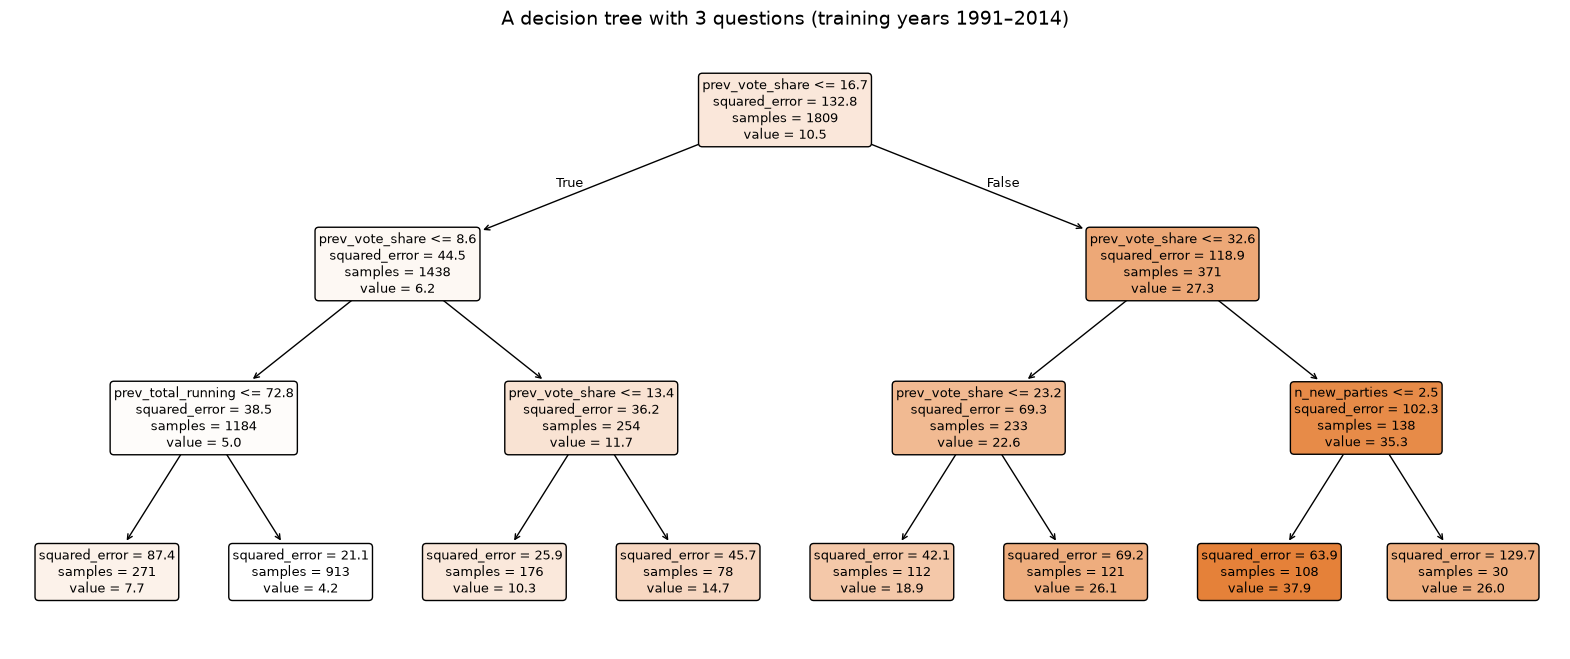

In [78]:
# How to read the result: the search keeps max_depth = 10 but asks for at least 30 parties per leaf: each
# prediction is an average over many parties, so the tree can't memorise even with 10 questions. Train and
# test errors are close (3.71 and 3.55: no overfitting), and the test MAE is just under the baseline (3.59).
#
# D5c. Drawing a small tree
#
# What this step does: trains a tree with only 3 questions and draws it. How to read each box:
# - first line: the question. Yes (True) → go to the left box, no (False) → go to the right box
# - squared_error: how spread out the vote shares are in the box (lower = parties more alike)
# - samples: how many training parties are in the box
# - value: the prediction for this box = the average vote share of those parties (in %)
# - colour: darker orange = higher predicted vote share

small_tree = build_pipeline(DecisionTreeRegressor(max_depth=3, min_samples_leaf=30, random_state=0),
                            scaler=None).fit(X_train, y_train)
tree_feature_names = [name.replace("numeric__", "").replace("family__family_name_", "family = ")
                      for name in small_tree.named_steps["prep"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(small_tree.named_steps["model"], feature_names=tree_feature_names, filled=True, rounded=True,
          precision=1, fontsize=9, ax=ax)
ax.set_title("A decision tree with 3 questions (training years 1991–2014)", fontsize=14)
plt.show()


In [79]:
# How to read the tree (from the top):
# - Top box: all 1,809 training parties, average 10.5%. First question: "was the party at 16.7% or less last
#   time?". Last time's score is the most useful clue.
# - Second level: both sides ask about last time's score again, to sort parties by size: small (≤ 8.6%),
#   medium (8.6–16.7%), large (16.7–32.6%) and very large (> 32.6%).
# - Third level: for small parties, when the parties running held less than 73% of the last vote
#   (prev_total_running), many votes are "up for grabs" and small parties get more (7.7% vs 4.2%). For very
#   large parties, if 3 or more newcomers run (n_new_parties), they fall from about 38% to 26%.
# - The 8 leaves at the bottom are the 8 possible predictions, from 4.2% to 37.9%.
# So the two features we created in D1 really are used.
#
# PART E – ENSEMBLES: MANY TREES TOGETHER
#
# The idea: one tree is unstable and makes big mistakes. If we combine many trees, their mistakes partly
# cancel out ("wisdom of the crowd"). Two families:
# - In parallel (independent trees, then the average):
#   - Bagging: each tree learns from a random sample of the parties
#   - Random Forest: the same, plus each question only sees a random part of the features
# - One after another (boosting):
#   - AdaBoost: each new tree concentrates on the parties the previous trees got most wrong
#   - Gradient Boosting: each new tree predicts the remaining error of the trees before it, and corrects it
# 
# E1. Bagging
#
# What it does: 200 trees, each learning from a random sample of the training parties (drawn with
# replacement: some parties twice, some not at all). The prediction is the average of the 200 trees.
# Settings chosen by cross-validation: the size of each tree (depth 6 or no limit, 5 or 20 parties per
# leaf) and max_samples (the share of the parties each tree gets: half or all).

bagging_search = tune(BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, random_state=0, n_jobs=-1),
                      {"model__estimator__max_depth": [6, None], "model__estimator__min_samples_leaf": [5, 20],
                       "model__max_samples": [0.5, 1.0]})
bagging_predictions = evaluate_model("Bagging – tuned", bagging_search.best_estimator_)


Best settings: {'estimator__max_depth': None, 'estimator__min_samples_leaf': 5, 'max_samples': 1.0} | cross-validation MAE 3.86
Bagging – tuned: test MAE 3.46 | RMSE 4.98 | R² 0.749 | train MAE 2.69


In [80]:
# How to read the result: the best version uses trees with no depth limit and at least 5 parties per leaf,
# each trained on a sample as big as the training set. Averaging 200 trees already beats the single tree:
# 3.46 points instead of 3.55.
#
# E2. Random Forest
#
# What it does: Bagging plus one trick: at each question, a tree may only choose among a random part of
# the features (max_features). In Bagging, every tree asks the same first question (about
# prev_vote_share), so the trees look alike and make the same mistakes. Hiding some features forces the
# trees to use the other clues too, so they are more different and their average is better.
# Settings: max_features (a third, 60% or all of the features), the depth and the leaf size.

forest_search = tune(RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1),
                     {"model__max_features": [0.33, 0.6, 1.0], "model__max_depth": [6, 10, None],
                      "model__min_samples_leaf": [5, 10]})
forest_predictions = evaluate_model("Random Forest – tuned", forest_search.best_estimator_)


Best settings: {'max_depth': None, 'max_features': 0.6, 'min_samples_leaf': 5} | cross-validation MAE 3.82
Random Forest – tuned: test MAE 3.42 | RMSE 4.94 | R² 0.753 | train MAE 2.75


In [81]:
# How to read the result: the best version lets each question see 60% of the features, not all of them.
# So the random-feature trick helps: 3.42 points instead of 3.46 for Bagging, and the best RMSE (4.94) and R²
# (0.75) so far.
#
# E3. AdaBoost
#
# What it does: builds trees one after another. After each tree, the parties predicted badly get more
# weight, so the next tree concentrates on them. The final prediction is a weighted combination of the
# trees. Settings: the depth of each tree (3 to 6), the number of trees, the learning rate (how much each
# tree counts: small = careful) and the loss (linear = weight in proportion to the error, square = big
# mistakes get much more weight).

ada_search = tune(AdaBoostRegressor(DecisionTreeRegressor(), random_state=0),
                  {"model__estimator__max_depth": [3, 4, 5, 6], "model__n_estimators": [50, 200],
                   "model__learning_rate": [0.03, 0.3], "model__loss": ["linear", "square"]})
ada_predictions = evaluate_model("AdaBoost – tuned", ada_search.best_estimator_)


Best settings: {'estimator__max_depth': 6, 'learning_rate': 0.03, 'loss': 'square', 'n_estimators': 50} | cross-validation MAE 3.92
AdaBoost – tuned: test MAE 3.49 | RMSE 5.05 | R² 0.741 | train MAE 3.24


In [82]:
# How to read the result: a small learning rate (0.03) wins: AdaBoost works best when each tree only
# corrects a little. It ends at 3.42 points, tied with the Random Forest. It is sensitive to the few parties
# with huge surprises (alliances, collapses), which our data can't explain.
#
# E4. Gradient Boosting – step 1: the loss, the number of trees and the learning rate
#
# What it does: trees one after another, but instead of re-weighting parties like AdaBoost, each new tree
# predicts the remaining error of the trees before it. Adding up all the small corrections gives the final
# prediction.
# What this step does: GridSearchCV tries 36 combinations:
# - loss: what the model tries to minimise. squared_error = the average outcome (default), absolute_error
#   = the median outcome, huber = a mix. Since we are judged on MAE and vote changes have big outliers
#   (parties collapsing or exploding), absolute_error should fit our problem better.
# - n_estimators: 200 or 400 trees; learning_rate: 0.03 or 0.1; max_depth: 2, 3 or 4

boosting_search = GridSearchCV(
    build_pipeline(GradientBoostingRegressor(random_state=42)),
    param_grid={"model__loss": ["squared_error", "absolute_error", "huber"], "model__n_estimators": [200, 400],
                "model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3, 4]},
    cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
boosting_search.fit(X_train, y_train, groups=groups)
print("Best settings:", {k.replace("model__", ""): v for k, v in boosting_search.best_params_.items()})
print(f"Cross-validation MAE: {-boosting_search.best_score_:.2f} points")

pd.DataFrame(boosting_search.cv_results_).groupby("param_model__loss")["mean_test_score"].max().mul(-1).round(2) \
    .rename("best cross-validation MAE")


Best settings: {'learning_rate': 0.03, 'loss': 'absolute_error', 'max_depth': 4, 'n_estimators': 400}
Cross-validation MAE: 3.66 points


param_model__loss
absolute_error    3.66
huber             3.71
squared_error     3.84
Name: best cross-validation MAE, dtype: float64

In [83]:
# How to read the result: the best version uses absolute_error, 400 trees and a learning rate of 0.03. The
# small table shows the loss really mattered: 3.66 with absolute_error against 3.84 with the default
# squared_error. Depth 4 was the largest depth tried here, so the next step checks deeper trees.
#
# E5. Gradient Boosting – step 2: the depth of the trees
#
# What this step does: keeps the settings of E4 and tries depths 2 to 6. When two depths have almost the
# same cross-validation error, the difference is just luck (it changes if the folds change). Then we keep
# the simplest model (the smallest depth): it is less likely to memorise and easier to explain.
# Our rule: the smallest depth whose cross-validation error is within 1% of the best one. The function
# below does that, and GridSearchCV uses it instead of simply taking the lowest number.


def simplest_within_1_percent(cv_results):
    """Index of the smallest max_depth whose cross-validation MAE is within 1% of the best one."""
    mae = -np.asarray(cv_results["mean_test_score"])
    depth_values = np.asarray(cv_results["param_model__max_depth"], dtype=float)
    good_enough = np.flatnonzero(mae <= mae.min() * 1.01)
    return int(good_enough[np.argmin(depth_values[good_enough])])


gb_settings = {k.replace("model__", ""): v for k, v in boosting_search.best_params_.items() if k != "model__max_depth"}
gb_search = tune(GradientBoostingRegressor(random_state=42, **gb_settings),
                 {"model__max_depth": [2, 3, 4, 5, 6]}, refit=simplest_within_1_percent)
best_gb = gb_search.best_estimator_
gb_predictions = evaluate_model("Gradient Boosting – tuned", best_gb)
pd.DataFrame({"max_depth": gb_search.cv_results_["param_model__max_depth"],
              "cross-validation MAE": -gb_search.cv_results_["mean_test_score"]}).round(3)


Best settings: {'max_depth': 4} | cross-validation MAE 3.66
Gradient Boosting – tuned: test MAE 3.15 | RMSE 4.97 | R² 0.749 | train MAE 2.99


,max_depth,cross-validation MAE
0,2,3.752
1,3,3.692
2,4,3.660
3,5,3.649
4,6,3.641


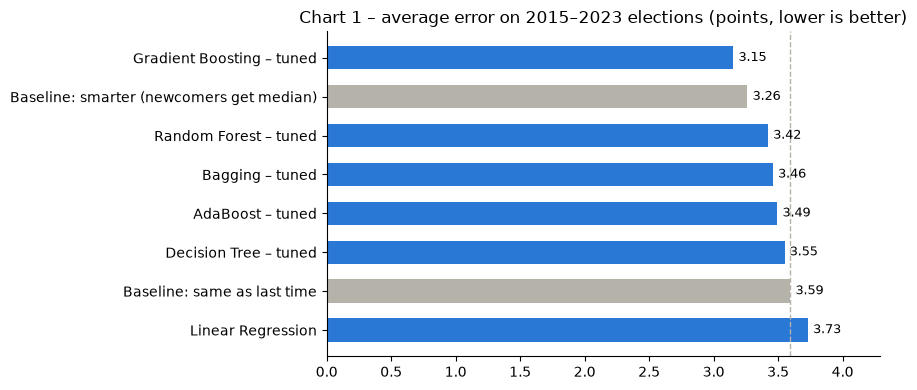

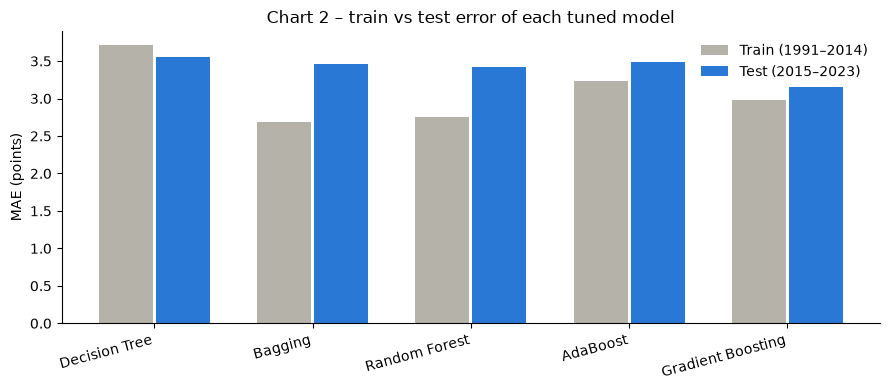

,test MAE,MAE existing parties,MAE new parties,test RMSE,test R²,train MAE,gap (test − train),vs baseline 1
Gradient Boosting – tuned,3.15,3.25,2.85,4.97,0.75,2.99,0.17,-12%
Baseline: smarter (newcomers get median),3.26,3.38,2.90,5.23,0.72,3.86,-0.60,-9%
Random Forest – tuned,3.42,3.41,3.46,4.94,0.75,2.75,0.67,-5%
Bagging – tuned,3.46,3.46,3.46,4.98,0.75,2.69,0.77,-4%
AdaBoost – tuned,3.49,3.47,3.55,5.05,0.74,3.24,0.26,-3%
Decision Tree – tuned,3.55,3.58,3.46,5.21,0.72,3.71,-0.16,-1%
Baseline: same as last time,3.59,3.38,4.29,5.59,0.68,4.25,-0.65,+0%
Linear Regression,3.73,3.71,3.79,5.19,0.73,4.01,-0.28,+4%


In [84]:
# How to read the result: depths 2 and 3 are clearly worse (3.75 and 3.69 in cross-validation): trees that
# small are too simple. Depths 4, 5 and 6 are practically tied (3.66, 3.65 and 3.64), less than 1% apart,
# which is just luck of the folds. The rule keeps the simplest: depth 4. On the test years it reaches 3.15
# points, the best so far, and its train error (2.99) stays close: it learned general rules.
#
# E6. Comparing all the models
#
# What this step does: puts every model in one table, sorted by test MAE, with all the metrics of Part C,
# the MAE for existing and new parties, and the gap = test MAE − train MAE (a big gap = overfitting).
# Chart 1: the test MAE of each model. Chart 2: train vs test MAE of each tuned model.

comparison = pd.DataFrame(scores).T
comparison["gap (test − train)"] = comparison["test MAE"] - comparison["train MAE"]
comparison["vs baseline 1"] = (comparison["test MAE"] / comparison.loc["Baseline: same as last time", "test MAE"] - 1
                               ).map("{:+.0%}".format)
comparison = comparison.sort_values("test MAE")

chart = comparison["test MAE"].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(chart.index, chart.values, color=[GREY if "Baseline" in n else BLUE for n in chart.index], height=0.6)
for y, value in enumerate(chart.values):
    ax.text(value + 0.04, y, f"{value:.2f}", va="center", fontsize=9)
ax.axvline(scores["Baseline: same as last time"]["test MAE"], color=GREY, linestyle="--", linewidth=1)
ax.set(title="Chart 1 – average error on 2015–2023 elections (points, lower is better)", xlim=(0, chart.max() * 1.15))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

tuned_models = ["Decision Tree – tuned", "Bagging – tuned", "Random Forest – tuned", "AdaBoost – tuned",
                "Gradient Boosting – tuned"]
positions = np.arange(len(tuned_models))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(positions - 0.18, comparison.loc[tuned_models, "train MAE"], width=0.34, color=GREY, label="Train (1991–2014)")
ax.bar(positions + 0.18, comparison.loc[tuned_models, "test MAE"], width=0.34, color=BLUE, label="Test (2015–2023)")
ax.set_xticks(positions, [m.replace(" – tuned", "") for m in tuned_models], rotation=15, ha="right")
ax.set(title="Chart 2 – train vs test error of each tuned model", ylabel="MAE (points)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

comparison.round(2)


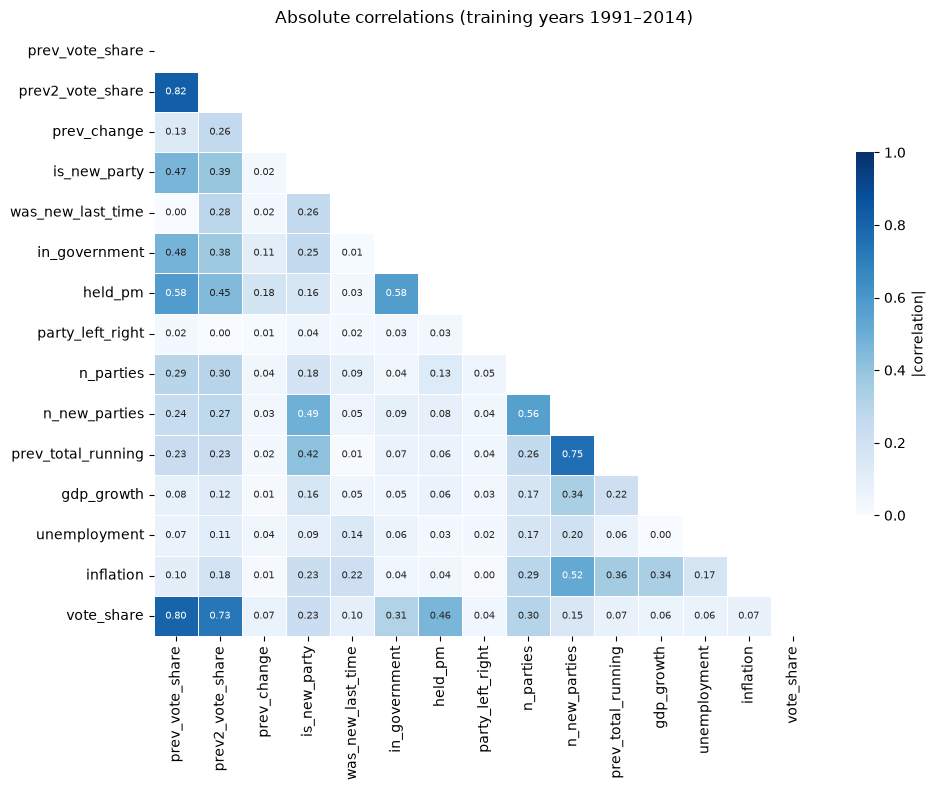

In [85]:
# How to read the table and the charts:
# - Test MAE (the main metric): Gradient Boosting is the best (3.15 points), 12% better than "same as last
#   time" (3.59) and also better than the smarter baseline (3.26). Then AdaBoost and Random Forest (3.42),
#   Bagging (3.46), the tuned tree (3.55). Linear Regression (3.73) is the only model worse than the baseline.
# - MAE existing / new parties: Gradient Boosting is the best on both (3.25 and 2.85).
# - RMSE and R²: the four ensembles are almost tied (RMSE 4.94–4.99, R² 0.75). Gradient Boosting aims at
#   the median (absolute-error loss), so it is best on the typical party, not on the rare big surprises.
# - Gap (test − train): Bagging and Random Forest remember the training years well (gaps 0.77 and 0.67),
#   but averaging keeps their test error low. Gradient Boosting has a small gap (0.17): it learned general
#   rules. The baselines have a negative gap: the test years were a bit easier for them than 1991–2014.
# Final party model: Gradient Boosting (absolute-error loss, 400 trees, learning rate 0.03, depth 4).
#
# PART F – UNDERSTANDING THE MODEL
#
# F1. The feature engineering ideas from class: the correlation heatmap
#
# In class (California housing + KNN), three techniques helped a lot: one-hot encoding fitted on the
# training data only (already in our pipeline), scaling, and feature selection with correlations. Do the
# last two also work on election data?
# What this step does: computes the correlation between every pair of numeric features, on the training
# years only, and draws it as a heatmap: one coloured square per pair. The signs are removed (absolute
# value): for feature selection, only the strength of the link matters. Only one triangle is shown, because
# the other half would be a mirror copy.

corr = train[NUMERIC_FEATURES + [TARGET]].corr().abs()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), vmin=0, vmax=1, cmap="Blues", annot=True,
            fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"shrink": 0.6, "label": "|correlation|"}, ax=ax)
ax.set_title("Absolute correlations (training years 1991–2014)")
plt.tight_layout()
plt.show()


In [86]:
# How to read the heatmap: find a name on the left and a name at the bottom; the square where they meet
# shows their correlation. Darker blue = stronger link.
# - The bottom row (vote_share) shows what is linked to the target: strong for prev_vote_share (0.80) and
#   prev2_vote_share (0.73); medium for held_pm (0.46), in_government (0.31), n_parties (0.30), is_new_party
#   (0.23); weak (under 0.1) for the economy, the left–right score and prev_change.
# - Near-copies (features carrying almost the same information): prev_vote_share ↔ prev2_vote_share (0.82),
#   n_new_parties ↔ prev_total_running (0.75), held_pm ↔ in_government (0.58). And a surprising one:
#   n_new_parties ↔ inflation (0.52): in the early 1990s Eastern Europe had both very high inflation and
#   many brand-new parties. A coincidence of history, not a cause.
# - Limits: the heatmap only sees straight-line links, one pair at a time. Our idea "a bad economy hurts
#   the parties in government" combines two features, so it can't see it. And correlation is not causation.
#
# F2. Feature selection with the class rule
#
# The rule: 1. drop features weakly linked to the target (below 0.1); 2. when two features are near-copies
# (above 0.7), drop the one less linked to the target. Computed on the training years only.


def select_by_correlation(train_table, min_target_corr=0.1, max_feature_corr=0.7):
    """Return the kept features and {dropped feature: reason}, following the class rule."""
    correlations = train_table[NUMERIC_FEATURES + [TARGET]].corr().abs()
    target_corr = correlations[TARGET].drop(TARGET)
    dropped = {f: f"weak link with target ({target_corr[f]:.2f})"
               for f in NUMERIC_FEATURES if target_corr[f] < min_target_corr}
    candidates = [f for f in NUMERIC_FEATURES if f not in dropped]
    for i, first in enumerate(candidates):
        for second in candidates[i + 1:]:
            if correlations.loc[first, second] > max_feature_corr:
                weaker, stronger = sorted([first, second], key=lambda f: target_corr[f])
                dropped.setdefault(weaker, f"near-copy of {stronger} ({correlations.loc[first, second]:.2f})")
    return [f for f in NUMERIC_FEATURES if f not in dropped], dropped


selected_features, dropped_features = select_by_correlation(train)
print("Kept:", selected_features)
pd.Series(dropped_features, name="why it is dropped").to_frame()


Kept: ['prev_vote_share', 'is_new_party', 'in_government', 'held_pm', 'n_parties', 'n_new_parties']


,why it is dropped
prev_change,weak link with target (0.07)
was_new_last_time,weak link with target (0.10)
party_left_right,weak link with target (0.04)
prev_total_running,weak link with target (0.07)
gdp_growth,weak link with target (0.06)
unemployment,weak link with target (0.06)
inflation,weak link with target (0.07)
prev2_vote_share,near-copy of prev_vote_share (0.82)


In [87]:
# How to read the result: the rule keeps only 6 of the 14 numeric features. The whole economy goes, with
# the left–right score and prev2_vote_share (a near-copy of prev_vote_share). The party family is text, so
# it is not in the heatmap: we keep it.
#
# F3. KNN – does scaling help here too? And does the smaller feature set help?
#
# What KNN does: to predict a party's score, it finds the K most similar parties in the training data (its
# "neighbours") and averages their scores. "Similar" is a distance computed column by column, so the scale
# of each column matters.
# What this step does: 3 scaling options (none, MinMaxScaler like in class, StandardScaler) × 2 feature
# sets (all 14 or the 6 selected). For each, GridSearchCV picks the best number of neighbours K. Then we
# retrain the best Gradient Boosting on the 6 selected features only.

knn_rows = []
for feature_set_name, numeric_features in [("all 14 features", NUMERIC_FEATURES), ("6 selected features", selected_features)]:
    columns = numeric_features + CATEGORICAL_FEATURES
    for scaler in [None, "minmax", "standard"]:
        knn_search = GridSearchCV(build_pipeline(KNeighborsRegressor(), numeric_features, scaler=scaler),
                                  {"model__n_neighbors": [5, 10, 20, 40], "model__weights": ["uniform", "distance"]},
                                  cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
        knn_search.fit(train[columns], y_train, groups=groups)
        knn_rows.append({"features": feature_set_name, "scaling": scaler or "none",
                         "best k": knn_search.best_params_["model__n_neighbors"],
                         "test MAE": mean_absolute_error(y_test, clip_shares(knn_search.predict(test[columns])))})
knn_results = pd.DataFrame(knn_rows)

gb_selected = build_pipeline(GradientBoostingRegressor(**best_gb.named_steps["model"].get_params()), selected_features)
gb_selected.fit(train[selected_features + CATEGORICAL_FEATURES], y_train)
gb_selected_mae = mean_absolute_error(y_test, clip_shares(gb_selected.predict(test[selected_features + CATEGORICAL_FEATURES])))

display(knn_results.round(2))
pd.DataFrame({"test MAE": [scores["Gradient Boosting – tuned"]["test MAE"], gb_selected_mae,
                           knn_results["test MAE"].min(), knn_results.query("scaling != 'none'")["test MAE"].min(),
                           scores["Baseline: same as last time"]["test MAE"]]},
             index=["Gradient Boosting – all features", "Gradient Boosting – 6 selected features",
                    "KNN – best version", "KNN – best scaled version", "Baseline: same as last time"]).round(2)


,features,scaling,best k,test MAE
0,all 14 features,none,40,3.47
1,all 14 features,minmax,5,4.33
2,all 14 features,standard,10,3.90
3,6 selected features,none,40,3.70
4,6 selected features,minmax,10,4.29
5,6 selected features,standard,10,4.14


,test MAE
Gradient Boosting – all features,3.15
Gradient Boosting – 6 selected features,3.25
KNN – best version,3.47
KNN – best scaled version,3.90
Baseline: same as last time,3.59


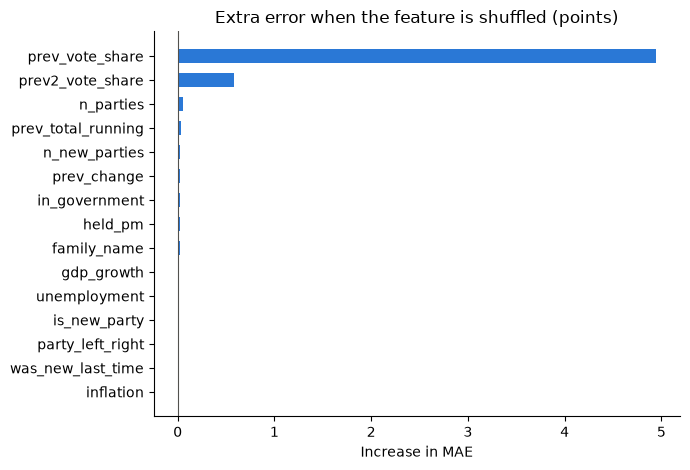

prev_vote_share       4.945
prev2_vote_share      0.579
n_parties             0.055
prev_total_running    0.032
n_new_parties         0.028
prev_change           0.028
in_government         0.027
held_pm               0.026
family_name           0.023
gdp_growth            0.015
unemployment          0.006
is_new_party          0.002
party_left_right      0.001
was_new_last_time    -0.000
inflation            -0.001
dtype: float64

In [88]:
# How to read the result:
# - Surprise: scaling makes KNN worse here, the opposite of what we saw in class. The best KNN has no
#   scaling (3.47). Without scaling, the columns with big numbers (vote shares from 0 to 68) count the most
#   in the distance, and that's exactly right for elections: last time's score is the best clue. Once we
#   scale, every column counts the same, so weak features (inflation, 0/1 flags) get as much say as the
#   past score, and the "neighbours" are less relevant. Lesson: scaling makes all features equal. That helps
#   when they are about equally useful (California housing) and hurts when one feature dominates.
# - Removing features makes Gradient Boosting worse (3.15 → 3.25): the features that look useless one by
#   one (economy, left–right, prev2_vote_share) still help a little in combination. That's the limit of
#   the heatmap. We keep all features.
#
# F4. Which features does the final model really use? Permutation importance
#
# What this step does: takes one column of the test data, shuffles it randomly (so it becomes nonsense),
# and measures how much worse the predictions get. If the error jumps, the model really relies on that
# column. It works on the original columns, so the party family counts as one feature.

importance = permutation_importance(best_gb, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=10,
                                    random_state=42, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set(title="Extra error when the feature is shuffled (points)", xlabel="Increase in MAE")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(3)


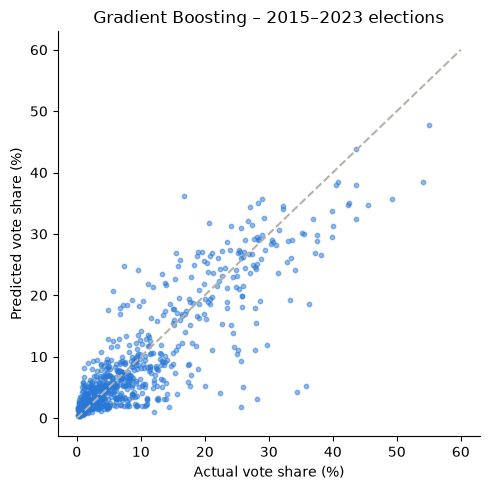

,average error,parties
prev_vote_share,,
new (0%),2.85,184
small (0–5%),1.66,216
medium (5–15%),3.22,195
large (15–30%),4.91,128
very large (30%+),6.39,43


,parties,average_score,model_error,baseline_error,model error in % of the score
bloc,,,,,
Far left,86,7.12,2.36,2.62,33%
Left,191,10.54,3.25,4.03,31%
Centre,103,10.06,3.74,4.21,37%
Right,206,12.08,3.47,3.58,29%
Far right,104,8.05,3.35,4.02,42%
Other,76,3.77,1.87,2.23,50%


In [89]:
# How to read the chart: shuffling prev_vote_share adds about 4.9 points of error: the model depends on it
# massively. prev2_vote_share comes second (0.6). All the others add less than 0.06 point each: they only
# make small corrections (the number of parties, how many votes are up for grabs, being in government, the
# family, the economy).
#
# F5. Where does the model make mistakes? By party size and by bloc
#
# What this step does:
# 1. Scatter plot: each dot is one party in one test election. Horizontal = what it really got, vertical =
#    what the model predicted. Dots on the dashed line are perfect predictions.
# 2. Average error by party size (size = the score last time).
# 3. Average error by bloc, for the model and for "same as last time", with the average score of a party
#    of that bloc. "Error in % of the score" = the error divided by the average score: a 3-point miss is
#    big for a 5% party, small for a 30% party.

test_errors = test.assign(prediction=gb_predictions,
                          error=lambda d: (d[TARGET] - d["prediction"]).abs(),
                          baseline_error=lambda d: (d[TARGET] - d["prev_vote_share"]).abs())

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, gb_predictions, s=10, alpha=0.5, color=BLUE)
ax.plot([0, 60], [0, 60], color=GREY, linestyle="--")
ax.set(xlabel="Actual vote share (%)", ylabel="Predicted vote share (%)", title="Gradient Boosting – 2015–2023 elections")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

size_band = pd.cut(test_errors["prev_vote_share"], [-0.1, 0, 5, 15, 30, 100],
                   labels=["new (0%)", "small (0–5%)", "medium (5–15%)", "large (15–30%)", "very large (30%+)"])
display(test_errors.groupby(size_band, observed=True)["error"].agg(["mean", "count"]).round(2)
        .rename(columns={"mean": "average error", "count": "parties"}))

error_by_bloc = test_errors.groupby("bloc").agg(
    parties=(TARGET, "size"), average_score=(TARGET, "mean"),
    model_error=("error", "mean"), baseline_error=("baseline_error", "mean")).reindex(BLOCS + ["Other"])
error_by_bloc["model error in % of the score"] = (error_by_bloc["model_error"] / error_by_bloc["average_score"]).map("{:.0%}".format)
error_by_bloc.round(2)


In [90]:
# How to read the results:
# - The scatter: most dots follow the dashed line. The dots far from it are parties that did much better or
#   worse than expected: alliances, collapses or surprise surges.
# - By size: bigger parties have bigger errors in points (6.4 for parties above 30%, 1.7 for small parties),
#   simply because they have more votes to win or lose.
# - By bloc: the model is better than "same as last time" in every bloc. It gains most on the Left (3.25 vs
#   4.03), the Far right (3.35 vs 4.02) and the Centre (3.74 vs 4.21): the blocs that changed most in
#   2015–2023. Relative to their size, the Far right (42% of the average score) and the Centre (37%) are the
#   hardest to predict: surges and new movements. The Right is the most stable (29%).
#
# F6. France 2017 and 2022, party by party
#
# What this step does: France's two elections are in the test years. We compare the model with "same as last
# time" for each French party, with its bloc.

for year in [2017, 2022]:
    france_year = test_errors[(test_errors["country_name_short"] == "FRA") & (test_errors["year"] == year)]
    print(f"France {year}: model MAE {france_year['error'].mean():.2f} | baseline {france_year['baseline_error'].mean():.2f}")

test_errors[(test_errors["country_name_short"] == "FRA") & (test_errors["year"] == 2022)][
    ["party_name_short", "party_name_english", "bloc", TARGET, "prev_vote_share", "prediction"]].rename(
    columns={TARGET: "real", "prev_vote_share": "baseline", "prediction": "model"}).round(1)


France 2017: model MAE 6.91 | baseline 7.82
France 2022: model MAE 6.49 | baseline 5.28


,party_name_short,party_name_english,bloc,real,baseline,model
1074,REM|R,The Republic Onwards! | Renaissance,Centre,25.8,28.2,18.2
1075,FI,Unbowed France,Far left,25.7,11.0,9.3
1076,FN,National Rally,Far right,18.7,13.2,11.7
1077,UMP|LR,Union for a Popular Movement | The Republicans,Right,10.4,15.8,19.1
1078,UDI,Union of Democrats and Independents,Right,0.9,3.0,5.0
1079,PE,Ecologist Party,Left,2.7,0.0,4.2
1080,R!,Reconquest,Far right,4.2,0.0,4.4


In [91]:
# How to read the result: the model beats the baseline in 2017 (6.91 vs 7.82, the year Macron's REM
# appeared) but does worse in 2022 (6.49 vs 5.28):
# - Centre (REM): the model knows parties in power lose votes, but it overdoes it (18.2% vs 25.8% real).
# - Right (LR): it predicts a recovery (19.1%) while the party kept falling (10.4%).
# - Far left (FI): 25.7% is the whole NUPES alliance, so nothing in FI's history announced it.
# - Far right (Reconquête, new): predicted 4.4%, real 4.2%. The newcomer logic works well.
# French politics has been reshaped since 2017, and the model learned from a more stable past.
#
# F7. "Accuracy" in % – easier to explain than MAE
#
# What this step does: turns the predictions into 4 yes/no questions, for the final model and the baseline,
# on the test years:
# 1. Within 2 points of the real result? (a very close guess)
# 2. Within 5 points? (a useful guess)
# 3. Right winner: in each election, is the party predicted first really the one that came first?
# 4. Right direction: for parties that ran last time, does the model say correctly if they go up or down?
#    (the baseline can't answer: it always predicts "no change")


def share_within(predictions, points):
    """% of parties whose prediction is at most `points` away from the real result."""
    return (np.abs(predictions - test_errors[TARGET]) <= points).mean()


def share_right_winner(prediction_column):
    """% of elections where the party with the highest prediction is the real winner."""
    right = test_errors.groupby("election_id").apply(
        lambda election: election.loc[election[prediction_column].idxmax(), "party_id"]
        == election.loc[election[TARGET].idxmax(), "party_id"])
    return right.mean()


ran_before = test_errors[test_errors["prev_vote_share"] > 0]
real_goes_up = ran_before[TARGET] > ran_before["prev_vote_share"]
model_says_up = ran_before["prediction"] > ran_before["prev_vote_share"]

accuracy_table = pd.DataFrame({
    "Gradient Boosting": [share_within(test_errors["prediction"], 2), share_within(test_errors["prediction"], 5),
                          share_right_winner("prediction"), (real_goes_up == model_says_up).mean()],
    "Baseline: same as last time": [share_within(test_errors["prev_vote_share"], 2),
                                    share_within(test_errors["prev_vote_share"], 5),
                                    share_right_winner("prev_vote_share"), np.nan],
}, index=["Within 2 points", "Within 5 points", "Right winner of the election", "Right direction (up/down)"])

print(f"{test_errors['election_id'].nunique()} test elections, {len(test_errors)} parties, {len(ran_before)} ran last time")
print(f"Always guessing 'down' gets the direction right {(~real_goes_up).mean():.0%} of the time")
accuracy_table.apply(lambda column: column.map(lambda value: "–" if pd.isna(value) else f"{value:.0%}"))


75 test elections, 766 parties, 582 ran last time
Always guessing 'down' gets the direction right 55% of the time


,Gradient Boosting,Baseline: same as last time
Within 2 points,53%,48%
Within 5 points,81%,76%
Right winner of the election,64%,65%
Right direction (up/down),59%,–


In [92]:
# How to read the result:
# - Within 2 points: 53% for the model vs 48% for the baseline. About half of the predictions are very close.
# - Within 5 points: 81% vs 76%. For the presentation: "8 times out of 10, the model is within 5 points of
#   the real result".
# - Right winner: 64% vs 65%, no better than "same as last time". The model is good at sizes but can't see
#   the big swings that change who comes first.
# - Right direction: 59%. Only a little better than a simple guess, because 55% of parties go down anyway.
# The model beats the baseline on closeness, the job it was trained for (absolute-error loss). It was never
# trained to pick winners.
#
# F8. Save the final party model
#
# What this step does: saves the tuned Gradient Boosting (preparation steps + model) to a file, so it can be
# reused without training again.

MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(best_gb, PARTY_MODEL_PATH)
print("Saved", PARTY_MODEL_PATH)
print({k: best_gb.named_steps["model"].get_params()[k] for k in ["loss", "n_estimators", "learning_rate", "max_depth"]})


Saved /Users/lena/Documents/IRONHACK DATA /Ironhack Data Analysis/WEEK 7/models/vote_share_gradient_boosting.joblib
{'loss': 'absolute_error', 'n_estimators': 400, 'learning_rate': 0.03, 'max_depth': 4}


In [93]:
# PART G – FRANCE 2027 WITH THE PARTY MODEL
#
# Question: if we use the final party model on the main French parties, what does it give for 2027, and is
# it close to the polls?
# Warnings, kept in mind all along:
# - The model learned from parliament elections; the Sondax polls are about the 2027 presidential
#   election. A candidate's score and a party's score are not the same thing.
# - ParlGov stops in 2022 for France. The 2024 snap election is the real "last result", so we type it in.
# - Part F showed the model did worse than the baseline in France 2022: this is an illustration.
#
# G1. The 2024 results and the assumptions for 2027
#
# a) 2024 results (first round, 30 June 2024, Ministry of the Interior), following the alliances like
#    ParlGov did in 2022: RN + Ciotti's allies 33.3% (29.26 + 3.96), Nouveau Front Populaire 28.0% (on the
#    "FI" line, like NUPES), Ensemble 20.0%, LR 6.6%, Reconquête 0.75% (very few candidates in 2024)
# b) In power before 2027: Renaissance holds the Prime Minister; LR ministers sat in the 2024–2025
#    governments (change LR to (0, 0) if no longer true when you present)
# c) The election: n_parties and n_new_parties copied from 2022; prev_total_running = 95% (almost everyone
#    runs again)
# d) The economy of 2026: approximate values (G3 shows they barely matter)
# Then, for each party, we start from its 2022 row (family, left–right…), put 2024 as the last result and
# 2022 as the result before, and ask the model.

france_2022 = df[(df["country_name_short"] == "FRA") & (df["year"] == 2022)]
RESULTS_2024_PARTIES = {"FN": 33.3, "FI": 28.0, "REM|R": 20.0, "UMP|LR": 6.6, "R!": 0.75}
IN_POWER_2027_PARTIES = {"FN": (0, 0), "FI": (0, 0), "REM|R": (1, 1), "UMP|LR": (1, 0), "R!": (0, 0)}
RACE_2027 = {"n_parties": france_2022["n_parties"].iloc[0], "n_new_parties": france_2022["n_new_parties"].iloc[0],
             "prev_total_running": 95.0}
ECONOMY_2026 = {"gdp_growth": 0.8, "unemployment": 7.6, "inflation": 1.0}
READABLE_NAMES = {"FN": "RN + allies", "FI": "United left (NUPES / NFP)", "REM|R": "Renaissance / Ensemble",
                  "UMP|LR": "Les Républicains", "R!": "Reconquête"}


def build_2027_party_rows(results_2024, in_power, race, economy):
    """One row per party, with the same columns the party model was trained on."""
    rows = france_2022.set_index("party_name_short").loc[list(results_2024)].copy()
    rows["prev2_vote_share"] = rows[TARGET]                      # 2022 becomes the result before last
    rows["prev_vote_share"] = pd.Series(results_2024)             # 2024 becomes the last result
    rows["prev_change"] = rows["prev_vote_share"] - rows["prev2_vote_share"]
    rows["is_new_party"] = 0
    rows["was_new_last_time"] = 0
    rows["in_government"] = [in_power[p][0] for p in rows.index]
    rows["held_pm"] = [in_power[p][1] for p in rows.index]
    for column, value in {**race, **economy}.items():
        rows[column] = value
    return rows


def predict_2027_parties(results_2024=RESULTS_2024_PARTIES, in_power=IN_POWER_2027_PARTIES, race=RACE_2027,
                         economy=ECONOMY_2026):
    rows = build_2027_party_rows(results_2024, in_power, race, economy)
    return pd.Series(clip_shares(best_gb.predict(rows[FEATURES])), index=rows.index)


rows_2027_parties = build_2027_party_rows(RESULTS_2024_PARTIES, IN_POWER_2027_PARTIES, RACE_2027, ECONOMY_2026)
party_projection = pd.DataFrame({
    "bloc": rows_2027_parties["bloc"],
    "2022 result": rows_2027_parties["prev2_vote_share"],
    "2024 result (baseline)": rows_2027_parties["prev_vote_share"],
    "Model 2027": predict_2027_parties(),
})
party_projection["Model − 2024"] = party_projection["Model 2027"] - party_projection["2024 result (baseline)"]
party_projection.rename(index=READABLE_NAMES).round(1)


,bloc,2022 result,2024 result (baseline),Model 2027,Model − 2024
party_name_short,,,,,
RN + allies,Far right,18.7,33.3,29.8,-3.5
United left (NUPES / NFP),Far left,25.7,28.0,28.0,0.0
Renaissance / Ensemble,Centre,25.8,20.0,18.7,-1.3
Les Républicains,Right,10.4,6.6,6.9,0.3
Reconquête,Far right,4.2,0.8,0.9,0.1


In [94]:
# How to read the result: "Model − 2024" is what the model adds to "same as last time":
# - RN + allies: 29.8% instead of 33.3%: it learned that very high scores reached after a big jump rarely last
# - Renaissance / Ensemble: 18.7% instead of 20.0%: the Prime Minister's party usually loses votes
# - United left (28.0%) and LR (6.9%): almost no change
# - Reconquête: 0.9%, because its 2024 score is tiny: the model can't know it ran almost no candidates
#
# G2. The polls, grouped like these parties
#
# What this step does: loads the Sondax polls. One row = one candidate in one "scenario" of one poll (a poll
# often tests several line-ups). We keep the first round and the last 3 months, group the candidates into
# the same 5 forces, add up each force's candidates in each scenario, average the scenarios of each poll,
# then average the polls (so each poll counts once). Then we compare with the model.
# - RN + allies: RN; United left: LFI, PS, Place Publique, Écologistes, PCF, GRS; Ensemble: Renaissance,
#   Horizons; LR; Reconquête; Other: LO, Debout la France, Villepin, Polony

polls = pd.read_csv(POLLS_PATH, parse_dates=["terrain_debut", "terrain_fin"])
recent_start = polls["terrain_fin"].max() - pd.DateOffset(months=3)
recent_polls = polls[(polls["tour"] == 1) & (polls["terrain_fin"] >= recent_start)].copy()
print(f"{polls['sondage_id'].nunique()} polls from {polls['terrain_fin'].min():%d %b %Y} to "
      f"{polls['terrain_fin'].max():%d %b %Y} | kept {recent_polls['sondage_id'].nunique()} first-round polls "
      f"since {recent_start:%d %b %Y}")

PARTY_TO_FORCE = {"RN": "FN", "LFI": "FI", "PS": "FI", "PP": "FI", "LE": "FI", "PCF": "FI", "GRS": "FI",
                  "RE": "REM|R", "HOR": "REM|R", "LR": "UMP|LR", "REC": "R!"}
recent_polls["force"] = recent_polls["parti"].map(PARTY_TO_FORCE).fillna("Other")
poll_force_average = (recent_polls.groupby(["sondage_id", "configuration", "force"])["score"].sum()
                      .unstack(fill_value=0).groupby("sondage_id").mean().mean())

party_vs_polls = party_projection[["bloc", "2024 result (baseline)", "Model 2027"]].copy()
party_vs_polls["Polls (last 3 months)"] = poll_force_average.reindex(party_vs_polls.index)
party_vs_polls["Model − polls"] = party_vs_polls["Model 2027"] - party_vs_polls["Polls (last 3 months)"]
party_vs_polls["Baseline − polls"] = party_vs_polls["2024 result (baseline)"] - party_vs_polls["Polls (last 3 months)"]
print(f"Average distance to the polls: model {party_vs_polls['Model − polls'].abs().mean():.1f} points | "
      f"baseline {party_vs_polls['Baseline − polls'].abs().mean():.1f} points")
party_vs_polls.rename(index=READABLE_NAMES).round(1)


46 polls from 27 Feb 2026 to 22 Oct 2026 | kept 29 first-round polls since 22 Jul 2026
Average distance to the polls: model 3.2 points | baseline 2.9 points


,bloc,2024 result (baseline),Model 2027,Polls (last 3 months),Model − polls,Baseline − polls
party_name_short,,,,,,
RN + allies,Far right,33.3,29.8,34.1,-4.3,-0.8
United left (NUPES / NFP),Far left,28.0,28.0,33.2,-5.2,-5.2
Renaissance / Ensemble,Centre,20.0,18.7,16.9,1.7,3.1
Les Républicains,Right,6.6,6.9,8.7,-1.9,-2.1
Reconquête,Far right,0.8,0.9,3.9,-3.0,-3.1


In [95]:
# How to read the result: 46 polls by 10 institutes, 29 first-round polls in the last 3 months. The polls
# give RN 34.1%, all left candidates together 33.2%, Ensemble 16.9%, LR 8.7%, Reconquête 3.9%.
# - RN + allies: the polls are close to 2024 (33.3%). The model is lower (29.8%); the polls don't show that
#   drop (yet).
# - United left: the polls are 5 points above 2024, but in a presidential election the left is split into
#   5 or 6 candidates, something a parliament alliance hides.
# - Ensemble: the model lowers it (18.7%), in the right direction, but the polls are lower still (16.9%).
# - Reconquête: the clearest limit: Zemmour polls about 4%, the model can't know why its 2024 score was tiny.
# - Average distance to the polls: model 3.2 points, baseline 2.9. The party model is not closer to the polls
#   than simply copying 2024.
#
# G3. How much do our assumptions matter?
#
# What this step does: changes one assumption at a time and predicts again. If a change moves the numbers by
# less than a point, that assumption doesn't matter much.

sensitivity = pd.DataFrame({
    "Our assumptions": predict_2027_parties(),
    "Bad economy": predict_2027_parties(economy={"gdp_growth": -1.0, "unemployment": 9.0, "inflation": 4.0}),
    "LR not in government": predict_2027_parties(in_power={**IN_POWER_2027_PARTIES, "UMP|LR": (0, 0)}),
    "Fewer parties running again": predict_2027_parties(race={**RACE_2027, "prev_total_running": 85.0}),
    "Reconquête at its 2022 score": predict_2027_parties(results_2024={**RESULTS_2024_PARTIES, "R!": 4.24}),
})
sensitivity.rename(index=READABLE_NAMES).round(1)


,Our assumptions,Bad economy,LR not in government,Fewer parties running again,Reconquête at its 2022 score
party_name_short,,,,,
RN + allies,29.8,31.3,29.8,29.2,29.8
United left (NUPES / NFP),28.0,28.1,28.0,27.4,28.0
Renaissance / Ensemble,18.7,18.6,18.7,18.1,18.7
Les Républicains,6.9,6.7,7.4,7.1,6.9
Reconquête,0.9,1.3,0.9,1.7,5.2


In [96]:
# How to read the table: the economy, LR's role and the race features move the results by about 1.5 points
# at most. The past results we feed in matter much more (Reconquête goes from 0.9% to 5.2% with its 2022
# score). So the alliances and the missing 2024 election matter more than any other assumption.
#
# Two limits of the party model for France:
# 1. Alliances: parties merge, split and change names (NUPES 2022, NFP 2024, Ensemble…), so their history
#    is lost and the model gets confused.
# 2. Parliament vs presidential: candidates are not parties.
#
# PART H – THE BLOC MODEL: PREDICTING BLOCS, MERGED WITH THE POLLS
#
# The idea that fixes both limits: instead of each party, we predict each political bloc (Far left, Left,
# Centre, Right, Far right, and Other). A bloc = all the parties of the same families added up. When left
# parties run together or separately, the blocs keep their history. And a presidential candidate can be put
# in a bloc just like a party, so the polls can be merged with our data.
#
# H1. Splitting the left alliances between Far left and Left
#
# The problem: in 2022 ParlGov stored the whole NUPES alliance (LFI, PCF, PS, Greens) in one row, "FI", so
# all of it is in the Far left and the Left looks almost gone. There is no official score per party inside
# the alliance, so we split it by the share of the alliance's candidates each bloc had (each party ran
# under the NUPES label in its own constituencies, so it collected roughly its share of the votes):
# - NUPES 2022 agreement: LFI about 360 constituencies + PCF 50 (Far left), Greens about 100 + PS 70 (Left)
#   → 71% Far left, 29% Left
# - the same rule is used for the NFP in 2024 (step H6)
# It is an approximation (LFI had more of the strong constituencies). The total of the two left blocs is
# more reliable than each one.

NUPES_2022 = {"Far left": (360 + 50) / 580, "Left": (100 + 70) / 580}           # share of the candidates
ALLIANCE_SPLITS = {("FRA", 2022, "FI"): NUPES_2022}                             # (country, year, row name)


def split_alliances(table, columns):
    """Split each alliance row into one row per bloc, multiplying `columns` by the bloc's share."""
    pieces = [table]
    for (country, year, name), shares in ALLIANCE_SPLITS.items():
        is_alliance = ((table["country_name_short"] == country) & (table["year"] == year)
                       & (table["party_name_short"] == name))
        pieces[0] = pieces[0][~is_alliance]
        for bloc, share in shares.items():
            part = table[is_alliance].copy()
            part["bloc"] = bloc
            part[columns] = part[columns] * share
            pieces.append(part)
    return pd.concat(pieces, ignore_index=True)


split_alliances(df, [TARGET]).query("country_name_short == 'FRA' and year == 2022")[
    ["party_name_short", "party_name_english", "family_name", "bloc", TARGET]].round(2)


,party_name_short,party_name_english,family_name,bloc,vote_share
1074,REM|R,The Republic Onwards! | Renaissance,Liberal,Centre,25.75
1075,FN,National Rally,Right-wing,Far right,18.68
1076,UMP|LR,Union for a Popular Movement | The Republicans,Conservative,Right,10.42
1077,UDI,Union of Democrats and Independents,Conservative,Right,0.87
1078,PE,Ecologist Party,Green/Ecologist,Left,2.67
1079,R!,Reconquest,Right-wing,Far right,4.24
2574,FI,Unbowed France,Communist/Socialist,Far left,18.14
2575,FI,Unbowed France,Communist/Socialist,Left,7.52


1256 bloc rows from 271 elections


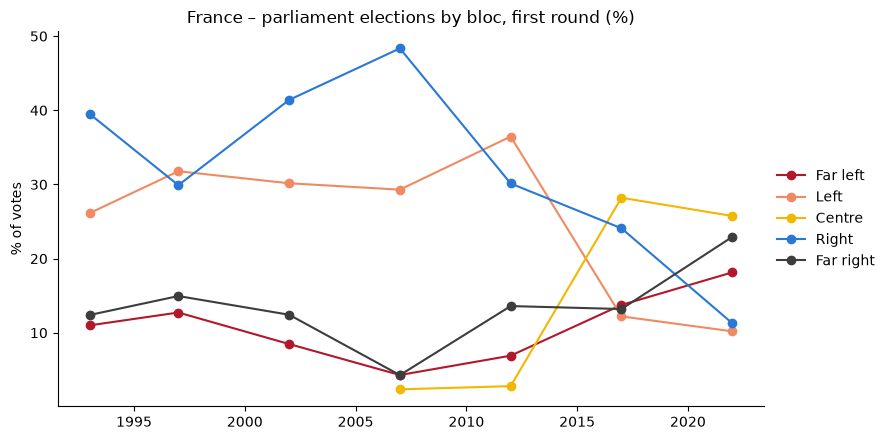

bloc,Far left,Left,Centre,Right,Far right
year,,,,,
1993,11.0,26.1,NaN,39.5,12.4
1997,12.7,31.8,NaN,29.9,15.0
2002,8.5,30.2,NaN,41.4,12.4
2007,4.3,29.3,2.4,48.4,4.3
2012,6.9,36.5,2.8,30.1,13.6
2017,13.8,12.2,28.2,24.1,13.2
2022,18.1,10.2,25.8,11.3,22.9


In [97]:
# How to read the result: the NUPES row ("FI", 25.66%) is now two rows: 18.14% Far left and 7.52% Left. The
# other French parties keep their bloc.
#
# H2. The bloc table
#
# What this step does: adds up the parties of each bloc in each election. One row = one bloc in one
# election, with:
# - vote_share: the bloc's score (the target)
# - prev_vote_share, prev2_vote_share: the bloc's score at the two previous elections of that country (taken
#   from the bloc table itself, so alliances and new names don't break the history)
# - prev_change, is_new_bloc, in_government / held_pm (1 if at least one party of the bloc was in the
#   outgoing government / held the PM), party_left_right (average position, weighted by votes)
# - n_parties, prev_total_running and the economy, like the party model
# For each country's first election in our window there is no previous bloc result, so we use the sum of
# the parties' previous results from Part A.


def build_bloc_table(party_rows):
    """One row per (election, bloc) with the bloc's result, past results and election information."""
    rows = party_rows.assign(lr_x_votes=party_rows["party_left_right"] * party_rows[TARGET],
                             votes_with_lr=party_rows[TARGET].where(party_rows["party_left_right"].notna()))
    bloc_rows = rows.groupby(["country_name_short", "election_id", "election_date", "year", "bloc"]).agg(
        vote_share=(TARGET, "sum"), prev_from_parties=("prev_vote_share", "sum"),
        prev2_from_parties=("prev2_vote_share", "sum"), in_government=("in_government", "max"),
        held_pm=("held_pm", "max"), lr_x_votes=("lr_x_votes", "sum"), votes_with_lr=("votes_with_lr", "sum"),
        n_parties=("n_parties", "first"), gdp_growth=("gdp_growth", "first"),
        unemployment=("unemployment", "first"), inflation=("inflation", "first"),
    ).reset_index()
    bloc_rows["party_left_right"] = bloc_rows["lr_x_votes"] / bloc_rows["votes_with_lr"].replace(0, np.nan)

    # Full grid: every bloc in every election of the country (0 if no party of that bloc ran), so "previous
    # election" really means the previous election, even if the bloc skipped one.
    election_list = bloc_rows[["country_name_short", "election_id", "election_date"]].drop_duplicates()
    grid = election_list.merge(pd.DataFrame({"bloc": bloc_rows["bloc"].unique()}), how="cross")
    grid = grid.merge(bloc_rows[["election_id", "bloc", TARGET]], on=["election_id", "bloc"], how="left")
    grid[TARGET] = grid[TARGET].fillna(0)
    grid = grid.sort_values(["country_name_short", "bloc", "election_date"])
    history = grid.groupby(["country_name_short", "bloc"])[TARGET]
    grid["prev_vote_share"] = history.shift(1)
    grid["prev2_vote_share"] = history.shift(2)

    bloc_rows = bloc_rows.merge(grid[["election_id", "bloc", "prev_vote_share", "prev2_vote_share"]],
                                on=["election_id", "bloc"], how="left")
    bloc_rows["prev_vote_share"] = bloc_rows["prev_vote_share"].fillna(bloc_rows["prev_from_parties"])
    bloc_rows["prev2_vote_share"] = bloc_rows["prev2_vote_share"].fillna(bloc_rows["prev2_from_parties"])
    bloc_rows["prev_change"] = bloc_rows["prev_vote_share"] - bloc_rows["prev2_vote_share"]
    bloc_rows["is_new_bloc"] = (bloc_rows["prev_vote_share"] == 0).astype(int)
    bloc_rows["prev_total_running"] = bloc_rows.groupby("election_id")["prev_vote_share"].transform("sum")
    return bloc_rows.drop(columns=["prev_from_parties", "prev2_from_parties", "lr_x_votes", "votes_with_lr"])


blocs = build_bloc_table(split_alliances(df, [TARGET]))
print(f"{len(blocs)} bloc rows from {blocs['election_id'].nunique()} elections")

france_blocs = blocs[(blocs["country_name_short"] == "FRA") & blocs["bloc"].isin(BLOCS)]
france_bloc_history = france_blocs.pivot(index="year", columns="bloc", values=TARGET)[BLOCS]

fig, ax = plt.subplots(figsize=(9, 4.5))
for bloc in BLOCS:
    ax.plot(france_bloc_history.index, france_bloc_history[bloc], marker="o", color=BLOC_COLORS[bloc], label=bloc)
ax.set(title="France – parliament elections by bloc, first round (%)", ylabel="% of votes")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
france_bloc_history.round(1)


In [98]:
# How to read the chart and the table: France's history by bloc.
# - Far left: small for a long time (4–13%), then 13.8% in 2017 (Mélenchon's first big score) and 18.1% in
#   2022 (its part of NUPES).
# - Left: around 30% until 2012, then a collapse to 12.2% in 2017 (PS from 29% to 7%) and 10.2% in 2022.
# - Centre: from 2.8% to 28.2% in 2017 (Macron's movement), 25.8% in 2022.
# - Right: from 48.4% (2007) down to 11.3% (2022). Far right: from 4.3% (2007) up to 22.9% (2022).
# Compared with the party chart of B7, the lines are much easier to follow: no jump of FI, no PS vanishing.
#
# H3. Train the bloc model
#
# What this step does: the same method as the party model, so the results can be compared:
# - same time split (train 1991–2014, test 2015–2023), same model (Gradient Boosting, absolute-error loss,
#   400 trees, learning rate 0.03), depth chosen with the same 1% rule
# - the bloc name replaces the party family as the category the model knows

BLOC_NUMERIC_FEATURES = ["prev_vote_share", "prev2_vote_share", "prev_change", "is_new_bloc", "in_government",
                         "held_pm", "party_left_right", "n_parties", "prev_total_running",
                         "gdp_growth", "unemployment", "inflation"]
BLOC_FEATURES = BLOC_NUMERIC_FEATURES + ["bloc"]

bloc_train = blocs[blocs["year"] < TEST_START_YEAR]
bloc_test = blocs[blocs["year"] >= TEST_START_YEAR].copy()
print(f"train: {len(bloc_train)} bloc rows | test: {len(bloc_test)} bloc rows")

bloc_pipeline = Pipeline([
    ("prep", ColumnTransformer([("numeric", SimpleImputer(strategy="median"), BLOC_NUMERIC_FEATURES),
                                ("bloc", OneHotEncoder(handle_unknown="ignore"), ["bloc"])])),
    ("model", GradientBoostingRegressor(loss="absolute_error", n_estimators=400, learning_rate=0.03, random_state=42)),
])
bloc_search = GridSearchCV(bloc_pipeline, {"model__max_depth": [2, 3, 4, 5, 6]}, cv=cv,
                           scoring="neg_mean_absolute_error", refit=simplest_within_1_percent, n_jobs=-1)
bloc_search.fit(bloc_train[BLOC_FEATURES], bloc_train[TARGET], groups=bloc_train["election_id"])
bloc_model = bloc_search.best_estimator_
print("Cross-validation MAE by depth:", dict(zip(bloc_search.cv_results_["param_model__max_depth"],
                                                 (-bloc_search.cv_results_["mean_test_score"]).round(2))))
print("Chosen depth:", bloc_model.named_steps["model"].max_depth)
print(f"'Same as last time' on the training years: {mean_absolute_error(bloc_train[TARGET], bloc_train['prev_vote_share']):.2f}")


def metrics(y_true, y_pred):
    """MAE, RMSE and R² of Part C, in one small dict."""
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R²": r2_score(y_true, y_pred)}


bloc_test["bloc_model"] = clip_shares(bloc_model.predict(bloc_test[BLOC_FEATURES]))
pd.DataFrame({"Baseline: same as last time": metrics(bloc_test[TARGET], bloc_test["prev_vote_share"]),
              "Bloc model": metrics(bloc_test[TARGET], bloc_test["bloc_model"])}).T.round(2)


train: 900 bloc rows | test: 356 bloc rows
Cross-validation MAE by depth: {np.int64(2): np.float64(5.46), np.int64(3): np.float64(5.39), np.int64(4): np.float64(5.44), np.int64(5): np.float64(5.42), np.int64(6): np.float64(5.46)}
Chosen depth: 3
'Same as last time' on the training years: 5.72


,MAE,RMSE,R²
Baseline: same as last time,4.99,7.03,0.79
Bloc model,5.09,6.94,0.79


In [99]:
# How to read the result:
# - Depth: 3 is the best in cross-validation (5.39 points), so it is kept.
# - On the training years (cross-validation), the bloc model is better than "same as last time": 5.39
#   against 5.72.
# - But on the 2015–2023 test elections it is not, on the average error: 5.09 against 4.99. It only makes
#   slightly fewer big mistakes (RMSE 6.94 vs 7.03, same R² 0.79).
# - Why: 2015–2023 is the period of big changes seen in B5 (far right and far left rising, traditional
#   blocs falling). The patterns of 1991–2014 don't help much for the big forces anymore.
# - The errors are bigger than for parties (about 5 vs 3.6 points for the baseline), because a bloc is
#   bigger than a party, so it moves more points.
#
# H4. Bloc model or party model? A fair comparison
#
# What this step does: both models answer the same question, the bloc scores of 2015–2023. We take the
# party model's predictions for every test party (Part E), split NUPES the same way, and add them up by bloc.
# We also save the bloc model.

party_predictions_by_bloc = (split_alliances(test.assign(party_model=gb_predictions), ["party_model"])
                             .groupby(["election_id", "bloc"])["party_model"].sum().rename("party_model_summed"))
bloc_test = bloc_test.merge(party_predictions_by_bloc, on=["election_id", "bloc"], how="left")
main_blocs = bloc_test[bloc_test["bloc"].isin(BLOCS)]

joblib.dump(bloc_model, BLOC_MODEL_PATH)
pd.DataFrame({
    "Baseline: same as last time": metrics(main_blocs[TARGET], main_blocs["prev_vote_share"]),
    "Party model, added up by bloc": metrics(main_blocs[TARGET], main_blocs["party_model_summed"]),
    "Bloc model": metrics(main_blocs[TARGET], main_blocs["bloc_model"]),
}).T.round(2)


,MAE,RMSE,R²
Baseline: same as last time,5.20,7.15,0.78
"Party model, added up by bloc",5.12,7.13,0.78
Bloc model,5.32,7.08,0.78


In [100]:
# How to read the result: on the same 5 blocs of the 2015–2023 elections, the three methods are very close:
# 5.12 points (party model added up), 5.20 (same as last time), 5.32 (bloc model). The bloc model has the
# best RMSE (7.08: the fewest big mistakes), the party model added up the best MAE.
# So for the big political forces in recent years, no method is clearly better than "same as last time".
# The party model's clear gain (3.15 vs 3.59) comes from small and new parties. The bloc model is still the
# one we need for France: it follows alliances and can be merged with the polls.
#
# H5. France 2017 and 2022 by bloc
#
# What this step does: the real bloc scores of France's two test elections, next to the baseline, the bloc
# model and the party model added up.

france_bloc_test = bloc_test[(bloc_test["country_name_short"] == "FRA") & bloc_test["bloc"].isin(BLOCS)]
france_bloc_test[["year", "bloc", TARGET, "prev_vote_share", "bloc_model", "party_model_summed"]].rename(
    columns={TARGET: "real result", "prev_vote_share": "baseline", "bloc_model": "bloc model",
             "party_model_summed": "party model (added up)"}).round(1)


,year,bloc,real result,baseline,bloc model,party model (added up)
148,2017,Centre,28.2,2.8,3.9,3.0
149,2017,Far left,13.8,6.9,6.7,9.7
150,2017,Far right,13.2,13.6,10.0,8.6
151,2017,Left,12.2,36.5,34.2,31.2
152,2017,Right,24.1,30.1,36.0,37.9
153,2022,Centre,25.8,28.2,25.7,18.2
154,2022,Far left,18.1,13.8,11.6,6.6
155,2022,Far right,22.9,13.2,11.5,16.1
156,2022,Left,10.2,12.2,13.6,7.0
157,2022,Right,11.3,24.1,28.4,24.1


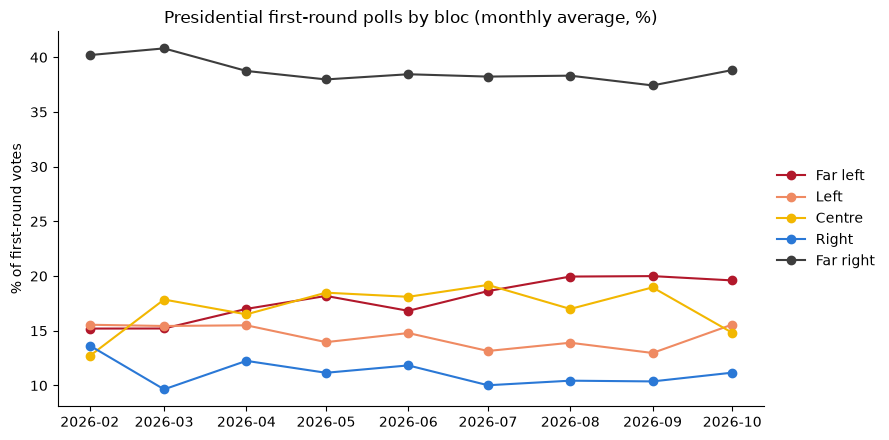

bloc
Far left     19.9
Left         14.1
Centre       16.9
Right        10.8
Far right    38.0
Other         0.4
Name: polls_2027, dtype: float64

In [101]:
# How to read the table:
# - 2022, Far left + Left: real 18.1% + 10.2% = 28.3%. The bloc model says 11.6% + 13.6% = 25.2%, much
#   closer than the party model added up (6.6% + 7.0% = 13.6%), which saw NUPES under the name "FI" and the
#   PS, Greens and PCF as gone. The bloc model misses the far left's rise inside the left: nothing in history
#   announced it.
# - 2022, Centre: real 25.8%, bloc model 25.7%, party model 18.2%.
# - 2022, Right and Far right: every method misses. The model expected the Right around 28% and the Far
#   right around 12%, but the Right collapsed (11.3%) and the Far right jumped (22.9%).
# - 2017: everyone misses the Centre (28.2% out of nowhere: Macron's movement) and the fall of the Left
#   (PS), expected at 34% and real 12%.
#
# H6. The polls by bloc, and how they moved
#
# What this step does: puts the 2027 candidates in the same blocs:
# - Far left: LFI (Mélenchon), PCF (Roussel), LO (Arthaud), GRS (Maurel, allied with LFI since 2022)
# - Left: PS, Place Publique (Glucksmann), Les Écologistes (Tondelier)
# - Centre: Renaissance (Attal), Horizons (Philippe)
# - Right: LR (Retailleau, Lisnard…), Debout la France (Dupont-Aignan)
# - Far right: RN (Le Pen), Reconquête (Zemmour)
# - Other: Villepin, Polony
# Same averaging as G2 (last 3 months, first round, each poll counts once), and a chart of the monthly
# average since the first poll, to check the last 3 months are not a strange moment.

PARTY_TO_BLOC = {"LFI": "Far left", "PCF": "Far left", "LO": "Far left", "GRS": "Far left",
                 "PS": "Left", "PP": "Left", "LE": "Left", "RE": "Centre", "HOR": "Centre",
                 "LR": "Right", "DLF": "Right", "RN": "Far right", "REC": "Far right"}
polls["bloc"] = polls["parti"].map(PARTY_TO_BLOC).fillna("Other")
first_round = polls[polls["tour"] == 1]
per_poll = (first_round.groupby(["sondage_id", "configuration", "bloc"])["score"].sum().unstack(fill_value=0)
                       .groupby("sondage_id").mean())
poll_dates = first_round.groupby("sondage_id")["terrain_fin"].first()
polls_2027 = per_poll[poll_dates.reindex(per_poll.index) >= recent_start].mean().rename("polls_2027")

monthly = per_poll.groupby(poll_dates.reindex(per_poll.index).dt.to_period("M")).mean()
fig, ax = plt.subplots(figsize=(9, 4.5))
for bloc in BLOCS:
    ax.plot(monthly.index.to_timestamp(), monthly[bloc], marker="o", color=BLOC_COLORS[bloc], label=bloc)
ax.set(title="Presidential first-round polls by bloc (monthly average, %)", ylabel="% of first-round votes")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
polls_2027.reindex(BLOCS + ["Other"]).round(1)


In [102]:
# How to read the chart and the result:
# - The chart: the Far right stays very high all year (38–41%). The Far left rises from about 15% (spring)
#   to 20% (autumn), the Centre moves between 13% and 19% depending on the candidates tested, the Left stays
#   around 13–16% and the Right around 10–12%. The last 3 months are stable enough to average.
# - The average of the last 3 months: Far right (Le Pen + Zemmour) 38.0%, Far left (Mélenchon, Roussel,
#   Arthaud, Maurel) 19.9%, Centre (Attal + Philippe) 16.9%, Left (Glucksmann, PS, Tondelier) 14.1%, Right
#   (Retailleau or Lisnard + Dupont-Aignan) 10.8%.
#
# H7. From presidential polls to parliament terms
#
# What this step does: a bloc doesn't get the same score in a presidential and a parliament election. We
# measure the difference in 2022, the only year with both elections:
# - presidential first round, 10 April 2022 (official results): Macron 27.85, Le Pen 23.15, Mélenchon 21.95,
#   Zemmour 7.07, Pécresse 4.78, Jadot 4.63, Lassalle 3.13, Roussel 2.28, Dupont-Aignan 2.06, Hidalgo 1.75,
#   Poutou 0.77, Arthaud 0.56
# - parliament first round, June 2022: our bloc table
# Gap = presidential − parliament, for each bloc. "Polls in parliament terms" = polls − gap.
# It's one election only, so it's a rough translation.

PRESIDENTIAL_2022 = {
    "Far left": 21.95 + 2.28 + 0.77 + 0.56,     # Mélenchon, Roussel, Poutou, Arthaud
    "Left": 4.63 + 1.75,                        # Jadot, Hidalgo
    "Centre": 27.85,                            # Macron
    "Right": 4.78 + 2.06,                       # Pécresse, Dupont-Aignan
    "Far right": 23.15 + 7.07,                  # Le Pen, Zemmour
}
translation = pd.DataFrame({
    "Presidential 2022": pd.Series(PRESIDENTIAL_2022),
    "Parliament 2022": france_blocs[france_blocs["year"] == 2022].set_index("bloc")[TARGET].reindex(BLOCS),
})
translation["Gap (presidential − parliament)"] = translation["Presidential 2022"] - translation["Parliament 2022"]
translation["Polls 2027 (presidential)"] = polls_2027.reindex(BLOCS)
translation["Polls 2027 in parliament terms"] = (translation["Polls 2027 (presidential)"]
                                                 - translation["Gap (presidential − parliament)"])
translation.round(1)


,Presidential 2022,Parliament 2022,Gap (presidential − parliament),Polls 2027 (presidential),Polls 2027 in parliament terms
Far left,25.6,18.1,7.4,19.9,12.4
Left,6.4,10.2,-3.8,14.1,18.0
Centre,27.8,25.8,2.1,16.9,14.8
Right,6.8,11.3,-4.4,10.8,15.2
Far right,30.2,22.9,7.3,38.0,30.7


8 times out of 10, for big blocs, reality was between -9.2 and +8.2 points of the model


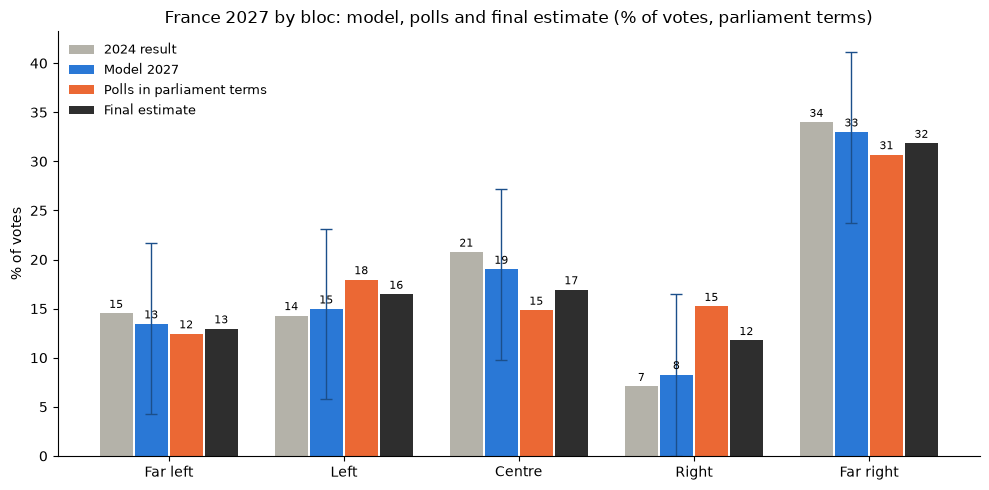

,2022 result,2024 result,Model 2027,Model range (8 in 10),Polls in parliament terms,Final estimate,"Final, in presidential terms"
Far left,18.1,14.5,13.5,4–22,12.4,12.9,20.4
Left,10.2,14.3,15.0,6–23,18.0,16.5,12.7
Centre,25.8,20.8,19.0,10–27,14.8,16.9,19.0
Right,11.3,7.1,8.3,0–16,15.2,11.8,7.3
Far right,22.9,34.0,33.0,24–41,30.7,31.8,39.1


In [103]:
# How to read the table: in 2022 the Far left got 7.4 points more in the presidential election than in the
# parliament election (Mélenchon's personal score), the Far right 7.3 more, the Centre 2.1 more. The Left got
# 3.8 points less and the Right 4.4 less: they do better in parliament elections, with many well-known local
# candidates. Once these gaps are removed, the 2027 polls give a parliament-type picture: Far right 30.7%,
# Left 18.0%, Right 15.2%, Centre 14.8%, Far left 12.4%.
# Careful: the two left blocs' 2022 parliament scores come from our NUPES split, so their gaps are
# approximate. Their total is more reliable than each one.
#
# H8. The final 2027 estimate
#
# What this step does:
# a) builds the 2027 row of each French bloc:
#    - last result = 2024 parliament election (first round, Ministry of the Interior), grouped by bloc like
#      our data (only real party lists, not the small "divers" lists, which ParlGov also leaves out). The NFP
#      (28.06%) is split like NUPES, by its candidates: LFI 229 + PCF 50 (Far left) against PS 170 +
#      Écologistes 92 (Left) → 52% / 48%
#      Far left = 52% of NFP + FI 0.04 + PCF 0.01; Left = 48% of NFP + Écologistes 0.01 + PS 0.09 + PRG 0.04
#      + other ecologists 0.57; Centre = Ensemble 20.04 + Horizons 0.72; Right = LR 6.57 + UDI 0.51;
#      Far right = RN 29.26 + Ciotti's allies 3.96 + Reconquête 0.75
#    - result before = 2022; in power: Centre holds the PM, the Right (LR) took part in the 2024–2025
#      governments; economy 2026 as in G1
# b) asks the bloc model for its prediction
# c) a range: on the test years, for big blocs (10% or more last time), 8 times out of 10 the real result
#    was between the two numbers printed below and the model's prediction. Added to the prediction, they
#    give a range "likely 8 times out of 10"
# d) final estimate = the average of the model and the polls in parliament terms. The model knows history
#    (power wears parties out, big scores rarely last); the polls know what happened since 2024. The 50/50
#    weight is a simple choice, not something we tested.

NFP_2024 = {"Far left": (229 + 50) / 541, "Left": (170 + 92) / 541}           # share of the candidates
RESULTS_2024_BLOCS = {
    "Far left": 28.06 * NFP_2024["Far left"] + 0.04 + 0.01,
    "Left": 28.06 * NFP_2024["Left"] + 0.01 + 0.09 + 0.04 + 0.57,
    "Centre": 20.04 + 0.72,
    "Right": 6.57 + 0.51,
    "Far right": 29.26 + 3.96 + 0.75,
}
IN_POWER_2027_BLOCS = {"Far left": (0, 0), "Left": (0, 0), "Centre": (1, 1), "Right": (1, 0), "Far right": (0, 0)}

rows_2027_blocs = france_blocs[france_blocs["year"] == 2022].set_index("bloc").loc[BLOCS].copy()
rows_2027_blocs["prev2_vote_share"] = rows_2027_blocs[TARGET]
rows_2027_blocs["prev_vote_share"] = pd.Series(RESULTS_2024_BLOCS)
rows_2027_blocs["prev_change"] = rows_2027_blocs["prev_vote_share"] - rows_2027_blocs["prev2_vote_share"]
rows_2027_blocs["is_new_bloc"] = 0
rows_2027_blocs["in_government"] = [IN_POWER_2027_BLOCS[b][0] for b in rows_2027_blocs.index]
rows_2027_blocs["held_pm"] = [IN_POWER_2027_BLOCS[b][1] for b in rows_2027_blocs.index]
rows_2027_blocs["prev_total_running"] = rows_2027_blocs["prev_vote_share"].sum()
for column, value in ECONOMY_2026.items():
    rows_2027_blocs[column] = value
rows_2027_blocs = rows_2027_blocs.reset_index()

big_blocs = bloc_test[bloc_test["prev_vote_share"] >= 10]
low, high = np.percentile(big_blocs[TARGET] - big_blocs["bloc_model"], [10, 90])
print(f"8 times out of 10, for big blocs, reality was between {low:+.1f} and {high:+.1f} points of the model")

final = pd.DataFrame({
    "2022 result": rows_2027_blocs["prev2_vote_share"].to_numpy(),
    "2024 result": rows_2027_blocs["prev_vote_share"].to_numpy(),
    "Model 2027": clip_shares(bloc_model.predict(rows_2027_blocs[BLOC_FEATURES])),
}, index=BLOCS)
final["Model range (8 in 10)"] = [f"{max(m + low, 0):.0f}–{m + high:.0f}" for m in final["Model 2027"]]
final["Polls in parliament terms"] = translation.loc[BLOCS, "Polls 2027 in parliament terms"]
final["Final estimate"] = (final["Model 2027"] + final["Polls in parliament terms"]) / 2
final["Final, in presidential terms"] = final["Final estimate"] + translation.loc[BLOCS, "Gap (presidential − parliament)"]

fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(BLOCS))
for k, (column, color) in enumerate([("2024 result", GREY), ("Model 2027", BLUE), ("Polls in parliament terms", ORANGE),
                                     ("Final estimate", DARK)]):
    bars = ax.bar(positions + (k - 1.5) * 0.2, final[column], width=0.19, color=color, label=column)
    ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=2)
ax.errorbar(positions - 0.1, final["Model 2027"], yerr=[np.minimum(-low, final["Model 2027"]), [high] * len(BLOCS)],
            fmt="none", ecolor="#1b4f8a", capsize=4, linewidth=1)
ax.set_xticks(positions, BLOCS)
ax.set(title="France 2027 by bloc: model, polls and final estimate (% of votes, parliament terms)", ylabel="% of votes")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
final.round(1)


In [104]:
# How to read the table and the chart: grey = 2024, blue = our model (the thin line is its "8 in 10" range),
# orange = the polls in parliament terms, black = our final estimate.
# - The model mostly follows 2024 with small moves: Far right 33.0%, Centre 19.0% (in power, it loses a
#   bit), Left 15.0%, Far left 13.5%, Right 8.3%.
# - Its range is wide (about −9 to +8 points): big political changes can't be predicted from history.
# - The polls in parliament terms are lower for the Centre (14.8%) and higher for the Right (15.2%) and the
#   Left (18.0%).
# - Final estimate in a parliament vote: Far right 31.8%, Centre 16.9%, Left 16.5%, Far left 12.9%, Right
#   11.8%. In the presidential first round (adding back the 2022 gaps): Far right 39.1%, Far left 20.4%,
#   Centre 19.0%, Left 12.7%, Right 7.3%.
#
# PART I – CONCLUSIONS
#
# What we built
# - One clean table of 2,575 party results in 271 European elections (31 countries, 1991–2023), with past
#   results, power, party family and bloc, and the economy of the year before.
# - A party model (Gradient Boosting) and a bloc model (the same method on the 5 blocs + Other).
#
# What we found
# - The last result is by far the best clue (permutation importance: 4.9 points of error when it's
#   shuffled). The result before comes second. Being in power costs about 3 points on average (B6). The
#   economy adds almost nothing on its own.
# - The best party model is Gradient Boosting with absolute-error loss: MAE 3.15 points on 2015–2023, 12%
#   better than "same as last time" (3.59), R² 0.75 vs 0.68. In simple words: 8 times out of 10 it is within
#   5 points of the real result (76% for the baseline).
# - Choosing the loss mattered more than adding features (3.66 vs 3.84 in cross-validation), and all the
#   settings were chosen by cross-validation, keeping the simplest when tied (depth 4).
# - Honest limits: the smarter baseline (newcomers get a typical score) already reaches 3.26; the model
#   doesn't pick winners better than the baseline (64% vs 65%); and for big blocs in 2015–2023 no method
#   beats "same as last time" on MAE (5.12 / 5.20 / 5.32). Big swings come from campaigns, leaders, scandals
#   and alliances, which are not in the data.
# - The class techniques behaved differently on election data: scaling made KNN worse (one feature
#   dominates), and dropping weakly correlated features made Gradient Boosting worse (they help in
#   combination).
# - Blocs fix the alliance problem: France 2022, far left + left predicted at 25.2% (real 28.3%), against
#   13.6% for the party model added up.
#
# France 2027 (an estimate of each bloc's strength, not of who wins)
# - The Far right is clearly first: about 32% in a parliament vote, 39% in the presidential first round.
# - Behind, four blocs are close in a parliament vote: Centre 17%, Left 16.5%, Far left 13%, Right 12%. In
#   the presidential first round the Far left comes second (20%, mostly Mélenchon), then the Centre (19%),
#   the Left (13%) and the Right (7%).
# - Uncertainty: the model's range is about −9 to +8 points; the far left / left split inside NUPES and NFP
#   is an approximation (their total, about 29% parliament and 33% presidential, is more reliable); the
#   2026 economy and LR being in government are assumptions; the 50/50 mix of model and polls is a choice;
#   the second round is not modelled.
#
# How to explain the model in the presentation
# - In one sentence: the model learns from 30 years of European elections how a party's (or a bloc's) score
#   usually moves from one election to the next, and applies these patterns to France.
# - What it looks at, in order: its last result (by far the strongest clue), the result before (rising or
#   falling?), being in power (parties in government usually lose votes), the size of the race (how many
#   parties, how many newcomers, how many votes are "up for grabs"), its family / bloc, and the economy
#   (very little on its own).
# - How it learns (Gradient Boosting): 400 small decision trees built one after another. The first makes a
#   rough guess; each next tree looks at the mistakes left and corrects a little of them. Each tree only
#   asks a few yes/no questions (4 for parties, 3 for blocs), so no tree can memorise individual elections.
# - How we know it works: trained on 1991–2014, tested on 2015–2023 (elections it never saw). MAE 3.15
#   points vs 3.59 for "same as last time"; 81% of predictions within 5 points.
# - What it cannot know: campaigns, candidates, scandals, alliances being made or broken. That's why, for
#   2027, we combine it with the polls.
#
# Possible next steps
# - Add the 2024 French election (and other recent elections) to the dataset properly.
# - Find a better source for the scores of each party inside alliances.
# - Test the bloc model on another country's latest election.
# - Predict the change in vote share instead of the share itself, or give the polls a weight learned from
#   past elections instead of 50/50.
